<!-- d2l:prose id=crawl-md-1 fw=all -->

# Document Extraction from Web Crawls

Open a news article in a browser and you see the article. The page the
server sent holds more: a navigation menu, a cookie banner, a column of
related links, a footer of legal notices, and perhaps a table or a block of
code inside the article itself. The models of that section
were trained mostly on such pages, and the web does not arrive as text.
Something has to decide which part of each page is the document.

That something is an *extractor*, a program that turns a page's HTML into
plain text, and its decision is final. A paragraph it drops is never seen by
the model, however long we train. A menu it keeps is learned as if someone
had written it as prose. Extraction decides what the model can ever learn,
before any filter, deduplication or tokenizer has a say.

This section follows one archive file of Common Crawl, the public crawl
behind nearly every open pretraining corpus, from its raw bytes to documents
with a manifest that lets anyone rebuild them. On the way we compare three
extractors with the text Common Crawl ships beside its archives, and we
identify the language, normalize the characters and remove the email
addresses of every document that survives. Our reference is FineWeb
[@Penedo.Kydlicek.BenAllal.ea.2024], a released corpus built from the
same archive file, so every record we keep has a production pipeline's text
beside ours.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import collections
import concurrent.futures
import gzip
import hashlib
import importlib.metadata
import io
import itertools
import json
import multiprocessing
import os
import pathlib
import re
import textwrap
import unicodedata
import warnings
import pandas as pd
from warcio.archiveiterator import ArchiveIterator

<!-- d2l:prose id=crawl-md-2 fw=all -->

Everything below runs on a CPU in a few minutes; the first run also
downloads 256 MiB of the archive and its 102 MB text file. Every step is
deterministic given the pinned bytes and package versions, and the last cell
checks every number against the registered copy. Setting `D2L_RERUN` makes
a run write new copies of the named result files instead.

In [3]:
CRAWL_MIB = 256  # bytes of the pinned WARC range read (multiple of 16)
LID_MIN = 0.65   # FineWeb's English threshold on the fastText score
N_WORKERS = min(8, os.cpu_count())
OFFLINE = os.environ.get('D2L_OFFLINE') == '1'  # only verified local bytes
ARTIFACTS = {  # name: (registered key, file a regeneration writes)
    'pin': ('lm-cc-warc-256m-v1', 'lm-cc-warc-256m-v1.pin.json'),
    'c0': ('lm-c0-docs-v1', 'lm-c0-docs-v1.jsonl.gz'),
    'crawl-results': ('lm-data-crawl-results-v1',
                      'lm-data-crawl-results-v1.json')}
RERUN = d2l.lm_rerun(ARTIFACTS)
print(f'CRAWL_MIB={CRAWL_MIB}, LID_MIN={LID_MIN}, N_WORKERS={N_WORKERS}, '
      f'OFFLINE={OFFLINE}, writing: {", ".join(sorted(RERUN)) or "none"}')

CRAWL_MIB=256, LID_MIN=0.65, N_WORKERS=8, OFFLINE=False, writing: none


<!-- d2l:prose id=crawl-md-3 fw=all -->

The registry holds no Common Crawl bytes. The entry `lm-cc-warc-256m-v1` is a
*pin*: the archive's URL, the byte range we read and a SHA-256 hash for every
16 MiB block of it. The bytes come from Common Crawl's servers and stay in a
local cache: Common Crawl grants no licence for the pages it archives. The book publishes only FineWeb's text for the records of our
range (under FineWeb's ODC-By licence) and files of counts, offsets and
hashes. The second cell pins, by revision, the datasets and models of the
whole chapter.

In [4]:

d2l.DATA_HUB['lm-cc-warc-256m-v1'] = (  # pin only: URLs, sizes, SHA-256s
    d2l.LM_DATA_URL + 'lm-cc-warc-256m-v1.pin.json',
    '9444225da3dd569d00b801ad9ae1455431dc1b01')
d2l.DATA_HUB['lid.176.ftz'] = (  # fastText, 176 languages, CC BY-SA 3.0
    'https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz',
    '86d1b630ba55a5040231eda9fe24a7befdc411f2')
d2l.DATA_HUB['lm-data-fineweb-ref-v1'] = (  # FineWeb rows of the range, ODC-By
    d2l.LM_DATA_URL + 'lm-data-fineweb-ref-v1.parquet',
    '45d4bbfee8c77d9f7d8955de9d03933254c77aaf')
d2l.DATA_HUB['lm-c0-docs-v1'] = (  # c0 rows: ids, offsets, hashes; no text
    d2l.LM_DATA_URL + 'lm-c0-docs-v1.jsonl.gz',
    '90120ce99b35b51e0e77da6f2c94f2a5f3e5f24c')
d2l.DATA_HUB['lm-data-crawl-results-v1'] = (  # the section's measured values
    d2l.LM_DATA_URL + 'lm-data-crawl-results-v1.json',
    '92c91643a63f00e8e1cd666cad58e22c18eeb43c')

In [5]:

LM_DATA_SOURCES = {  # name: (kind, Hub repository, revision, licence)
    'fineweb': ('dataset', 'HuggingFaceFW/fineweb',
                '9bb295ddab0e05d785b879661af7260fed5140fc', 'odc-by'),
    'fineweb-edu': ('dataset', 'HuggingFaceFW/fineweb-edu',
                    '87f09149ef4734204d70ed1d046ddc9ca3f2b8f9', 'odc-by'),
    'fineweb-2': ('dataset', 'HuggingFaceFW/fineweb-2',
                  'af9c13333eb981300149d5ca60a8e9d659b276b9', 'odc-by'),
    'edu-annotations': ('dataset', 'HuggingFaceFW/fineweb-edu-llama3-annotations',
                        '72df4c92fb1b48beceb16016e8f695ec40a6c3a5', 'odc-by'),
    'finemath': ('dataset', 'HuggingFaceTB/finemath',
                 'e92b25a616738fe95dc186b64dfb19f9c8525594', 'odc-by'),
    'codeparrot-clean': ('dataset', 'codeparrot/codeparrot-clean',
                         '35a59fb025bc0a102f7d96eac09d145b896d487b', 'per-file'),
    'belebele': ('dataset', 'facebook/belebele',
                 '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2', 'cc-by-sa-4.0'),
    'cosmopedia': ('dataset', 'HuggingFaceTB/cosmopedia',
                   '0ae6ec63f91742bd2d1eaef4f02232c55d719385', 'apache-2.0'),
    'mmlu': ('dataset', 'cais/mmlu',
             'c30699e8356da336a370243923dbaf21066bb9fe', 'mit'),
    'fineweb-edu-classifier': ('model', 'HuggingFaceFW/fineweb-edu-classifier',
                               '284663cbb2dabf9bda30d8f8cc49601251ee1631',
                               'apache-2.0')}

<!-- d2l:prose id=crawl-md-4 fw=all -->

## Crawl Archives

Since 2008 Common Crawl has crawled the web again and again, lately every
month or two and a few billion pages at a time. It publishes each crawl as
tens of thousands of archive files in the WARC format (Web ARChive, a
standard of the web-archiving community). A WARC file is a sequence of
*records*, and every fetch leaves three of them. A `request` record holds
the HTTP request the crawler sent, a `response` record the server's whole
reply, headers and body, and a `metadata` record what the crawler noted
about the fetch. One `warcinfo` record at the
start describes the crawl itself. Each record begins with a header that
holds a unique record id, the URL, the date and the length of what follows.

From each WARC file Common Crawl derives two more. A WAT file holds the
metadata and links of each page as JSON, and a WET file holds plain text in
`conversion` records, each pointing back to its response through a
`WARC-Refers-To` header. A WET file is about a tenth of the size of its WARC
file, and it is the cheapest way to get text out of a crawl. Several early
corpora used it. We will see what it keeps.

One design decision makes the format easy to sample. Each record is
compressed as its own gzip member, and a gzip file may be a concatenation of
members, so decompression can start at any member boundary. A client that
asks the server for the first $n$ bytes with an HTTP `Range` request gets a
valid sequence of complete records followed by one member that the cut has
split. That last member has to be counted and dropped, never parsed into half
a record. `iter_warc` does this. It decompresses member by member, parses
each record's WARC header and, for a response, the HTTP status line and
headers, and counts every record type in `stats`.

In [6]:

WarcRecord = collections.namedtuple(
    'WarcRecord', 'id type url date status mime offset length headers body')


def iter_warc(source, n_bytes=None, types=('response',), *, stats=None):
    """Yield the WARC records of the given types (None: all) from a local
    path or a URL, reading only the first n_bytes (a Range request for a
    URL). Each gzip member is decompressed on its own; offset and length
    are the member's compressed byte range. A member cut off by the end of
    the input is not yielded: it is counted in stats['truncated'], beside
    one count per record type (stats is a dict the caller passes)."""
    for offset, length, raw in d2l._gzip_members(
            d2l._warc_chunks(source, n_bytes)):
        if raw is None:
            if stats is not None:
                stats['truncated'] = stats.get('truncated', 0) + 1
            continue
        rec = d2l._warc_parse(raw, offset, length)
        if stats is not None:
            stats[rec.type] = stats.get(rec.type, 0) + 1
        if types is None or rec.type in types:
            yield rec

<!-- d2l:prose id=crawl-md-5 fw=all -->

`fetch_warc_range` reads the pin, requests the bytes block by block, and
checks each 16 MiB block against its hash before it writes the block to the
cache. A shorter prefix can therefore be verified on its own, and an
interrupted download resumes at the first missing block. With
`D2L_OFFLINE=1` the function uses only a verified local copy and otherwise
stops with instructions for fetching one.

In [7]:

def fetch_warc_range(pin='lm-cc-warc-256m-v1', n_bytes=None, cache_dir=None,
                     *, which='warc'):
    """Local path of the pinned Common Crawl bytes: which='warc' gives the
    first n_bytes of the pinned range (a multiple of the 16 MiB block; None
    for the whole range), fetched with Range requests and checked block by
    block against the pin's SHA-256s; which='wet' gives the whole WET file
    of the same segment, checked as one file. With D2L_OFFLINE=1 only a
    verified local copy is used. The bytes stay in cache_dir (default
    ../data/lm/cc); they are never committed or uploaded."""
    import pathlib
    with open(d2l.download_keyed(pin)) as f:
        spec = json.load(f)
    cache = pathlib.Path(cache_dir or os.path.join('..', 'data', 'lm', 'cc'))
    cache.mkdir(parents=True, exist_ok=True)
    offline = os.environ.get('D2L_OFFLINE') == '1'
    if which == 'wet':
        if n_bytes is not None:
            raise ValueError('the WET file is fetched and checked whole')
        return d2l._fetch_whole(spec['wet'], cache, offline)
    if which != 'warc':
        raise ValueError(f"which is 'warc' or 'wet', not {which!r}")
    warc, block = spec['warc'], spec['warc']['block_bytes']
    n_bytes = warc['n_bytes'] if n_bytes is None else n_bytes
    if n_bytes % block or not 0 < n_bytes <= warc['n_bytes']:
        raise ValueError(f'n_bytes must be a multiple of {block} up to '
                         f'{warc["n_bytes"]}')
    path = cache / f'{pin}.warc.gz'
    have = d2l._verified_blocks(path, warc['block_sha256'], block,
                                n_bytes // block)
    if have * block < n_bytes:
        if offline:
            raise RuntimeError(
                f'D2L_OFFLINE=1 and {path} holds {have} verified blocks of '
                f'{n_bytes // block}: run once with network access, or fetch '
                f'bytes 0-{n_bytes - 1} of {warc["url"]} into {path}')
        d2l._fetch_blocks(warc, path, have, n_bytes // block)
    return path

<!-- d2l:prose id=crawl-md-6 fw=all -->

We start with one record. The next cell parses the first 4 MiB of the range
and picks, by a rule it prints, the first successful HTML response that holds
a table or a block of preformatted text and that FineWeb kept. It shows the
record three ways: the HTML as a skeleton of its first 25 elements, each run
of text replaced by its length; the WET text as counts; and the text FineWeb
extracted from the same record. We print no text of our own from the crawl,
only FineWeb's, whose licence lets us show it.

In [8]:
path = d2l.fetch_warc_range(n_bytes=16 * 2**20)  # block 0, SHA-256 checked
head_stats = {}
head = list(d2l.iter_warc(path, n_bytes=4 * 2**20, types=None,
                          stats=head_stats))
print('records in the first 4 MiB:',
      ', '.join(f'{k} {v}' for k, v in head_stats.items()))
fineweb = pd.read_parquet(d2l.download_keyed('lm-data-fineweb-ref-v1')
                          ).set_index('id')

def pick(records):
    """First HTTP-200 HTML response with a <pre> or <table> element, at
    least 2,000 characters of trafilatura text and a FineWeb row."""
    for r in records:
        if (r.type, r.status, r.mime) != ('response', 200, 'text/html') or \
                r.id not in fineweb.index:
            continue
        page = d2l.decode_body(r.body, r.headers)[0]
        text = (d2l.extract_text(page, url=r.url)
                if re.search(r'<(pre|table)\b', page, re.I) else None)
        if text and len(text) >= 2000:
            return r, page, text

found, where = pick(head), 'the first 4 MiB'
if found is None:
    found, where = (pick(d2l.iter_warc(path, n_bytes=16 * 2**20)),
                    'the first 16 MiB block')
record, page, ours_text = found
print(f'rule: first HTTP-200 text/html response with <pre> or <table>,\n'
      f'  >= 2,000 characters of trafilatura text and a FineWeb row; found in '
      f'{where}')
print(f'record {record.id}\n  {record.url}\n')
print(f'(1) HTML: {len(record.body):,} bytes; first 25 elements of <body>:')
print('\n'.join(d2l.html_skeleton(page, 25)))
wet_record = next(r for r in d2l.iter_warc(d2l.fetch_warc_range(which='wet'),
                                    types=('conversion',))
           if r.headers.get('WARC-Refers-To') == record.id)
lines = wet_record.body.decode('utf-8').splitlines()
short = [len(l.strip()) < 30 for l in lines]
run = max(len(list(g)) for k, g in itertools.groupby(short) if k) \
    if any(short) else 0
print(f'\n(2) WET text: {sum(map(len, lines)):,} characters in {len(lines)} '
      f'lines, {np.mean(short):.0%} of them under 30 characters;\n'
      f'  longest run of short lines (a menu signature): {run}')
fw = fineweb.loc[record.id, 'text']
mask = lambda t: re.sub(r'\S+@\S+|\b(?:\d{1,3}\.){3}\d{1,3}\b', '<PII>',
                        t or '')  # FineWeb replaced emails and IPv4s too
f1 = d2l.char_ngram_f1(mask(ours_text), mask(fw))[2]
print(f'\n(3) FineWeb text: {len(fw):,} characters; our trafilatura text: '
      f'{len(ours_text):,} characters;\n  character-5-gram F1 against FineWeb '
      f'{f1:.2f}')
print('first 300 characters of FineWeb\'s text:')
print(textwrap.fill(repr(fw[:300]), 96, initial_indent='  ',
                    subsequent_indent='  '))
print('(text: FineWeb, HuggingFaceFW/fineweb CC-MAIN-2025-05, ODC-By 1.0)')

records in the first 4 MiB: warcinfo 1, request 286, response 285, metadata 285, truncated 1


rule: first HTTP-200 text/html response with <pre> or <table>,
  >= 2,000 characters of trafilatura text and a FineWeb row; found in the first 4 MiB
record <urn:uuid:b6a18b18-8f40-4156-aeca-92c7150ab355>
  http://2013.widerstand.org/manual/zh-cn/misc/security_tips.html

(1) HTML: 27,385 bytes; first 25 elements of <body>:
body
  div
    p
      a  [text: 7 chars]
      a  [text: 10 chars]
      a  [text: 3 chars]
      a  [text: 8 chars]
      a  [text: 7 chars]
    p  [text: 30 chars]
    img
  div
    a
      img
  div
    a  [text: 6 chars]
    a  [text: 11 chars]
    a  [text: 13 chars]
    a  [text: 11 chars]
    a  [text: 27 chars]
  div
    div
      h1  [text: 13 chars]
      div
        p
          span  [text: 20 chars]

(2) WET text: 14,217 characters in 127 lines, 34% of them under 30 characters;
  longest run of short lines (a menu signature): 6

(3) FineWeb text: 11,159 characters; our trafilatura text: 12,658 characters;
  character-5-gram F1 against FineWeb 0.96
first 3

<!-- d2l:prose id=crawl-md-7 fw=all -->

Before reading those three views, look at the record counts. The first 4 MiB
hold 285 responses, and 572 records that are not documents at all: requests,
metadata and the description of the crawl. A pipeline that counted records
would overstate its corpus threefold.

The record is a page of the Apache HTTP Server manual on security. Its URL
contains `zh-cn`, yet its text is English, and FineWeb kept it as English: a
URL is no guide to a page's language. The skeleton is the boilerplate made
visible. The body opens with five short links (the manual's menu bar), a line
of 30 characters, a logo and a trail of five more links (the breadcrumbs)
before the first heading. The WET text shows the signature of that
boilerplate. A third of its 127
lines are shorter than 30 characters, with a run of six in a row, which is
what a menu looks like once the layout is gone. FineWeb's text begins with
the 30-character line, "Apache HTTP Server Version 2.4", and continues with
the article. The menu, the breadcrumbs and, curiously, the heading "Security
Tips" are gone. Our own trafilatura text agrees with FineWeb's to a
character-5-gram F1 of 0.96, the harmonic mean of the shares of each text's
five-character substrings found in the other. The WET text is about 3,000
characters longer than FineWeb's.

Our reader is short enough to read and too new to trust. `warcio`, the
library that web archives use, serves as the oracle: on the same 4 MiB both
must yield the same records, with the same ids, types, offsets, lengths and
body hashes.

In [9]:
with open(path, 'rb') as f:
    it = ArchiveIterator(io.BytesIO(f.read(4 * 2**20)))
    theirs = []
    try:
        for r in it:
            body = hashlib.sha256(r.raw_stream.read()).hexdigest()
            offset = it.get_record_offset()
            it.read_to_end(r)
            theirs.append((r.rec_headers.get_header('WARC-Record-ID'),
                           r.rec_type, offset, it.get_record_length(), body))
    except Exception:  # warcio may raise inside the cut-off member
        pass
mine = [(r.id, r.type, r.offset, r.length, hashlib.sha256(r.body).hexdigest())
        for r in head]
same = sum(a == b for a, b in zip(mine, theirs))
print(f'{same}/{len(mine)} records identical (id, type, offset, length, '
      f'body SHA-256);\nwarcio also yields {len(theirs) - len(mine)} partial '
      f'record(s) from the cut-off member,\n  which iter_warc counts as '
      f'truncated ({head_stats.get("truncated", 0)})')
assert same == len(mine) and len(theirs) - len(mine) == head_stats.get(
    'truncated', 0)

857/857 records identical (id, type, offset, length, body SHA-256);
warcio also yields 1 partial record(s) from the cut-off member,
  which iter_warc counts as truncated (1)


<!-- d2l:prose id=crawl-md-8 fw=all -->

All 857 complete records agree. The one difference is the member the cut has
split: warcio hands it to the caller as a record, cut short, and a pipeline
that trusted it would store half a page. `iter_warc` counts it as truncated
instead.

Now the whole range, 256 MiB, a little under a quarter of the file.

In [10]:
path = d2l.fetch_warc_range(n_bytes=CRAWL_MIB * 2**20)
stats, index = {}, []
for r in d2l.iter_warc(path, n_bytes=CRAWL_MIB * 2**20, types=None,
                       stats=stats):
    index.append((r.id, r.type, r.url, r.date, r.status, r.mime, r.offset,
                  r.length, len(r.body)))
index = pd.DataFrame(index, columns=['id', 'type', 'url', 'date', 'status',
                                     'mime', 'offset', 'length', 'n_body'])
print(f'{CRAWL_MIB} MiB: {len(index):,} complete records, '
      f'{stats.get("truncated", 0)} truncated member at the cut')
print(index.type.value_counts().to_string(), '\n')
resp = index[index.type == 'response']
by_mime = resp.groupby(resp.mime.fillna('(none)')).agg(
    responses=('id', 'size'), status_200=('status', lambda s: (s == 200).sum()),
    median_body_bytes=('n_body', 'median'))
print(by_mime.sort_values('responses', ascending=False).head(6).to_string())
per_mib = len(resp) / CRAWL_MIB
print(f'\n{per_mib:.1f} responses per MiB; extrapolated to the whole '
      f'1,141,586,184-byte file:\n  about {per_mib * 1141586184 / 2**20:,.0f} '
      f'responses (assumes the prefix is representative)')
print('\nfirst 12 records (type, offset, compressed length):')
print(index[['type', 'offset', 'length']].head(12).to_string(index=False))

256 MiB: 29,195 complete records, 1 truncated member at the cut
type
request     9732
response    9731
metadata    9731
warcinfo       1 

                          responses  status_200  median_body_bytes
mime                                                              
text/html                      9591        9591            71308.0
application/pdf                  67          67           305371.0
application/atom+xml             14          14             4984.5
(none)                           10          10              669.5
application/octet-stream          8           8            15377.0
text/plain                        8           8              169.5

38.0 responses per MiB; extrapolated to the whole 1,141,586,184-byte file:
  about 41,383 responses (assumes the prefix is representative)

first 12 records (type, offset, compressed length):
    type  offset  length
warcinfo       0     471
 request     471     432
response     903    1903
metadata    2806     424
 reques

<!-- d2l:prose id=crawl-md-9 fw=all -->

The range holds 29,195 complete records, of which 9,731 are responses, and
every response has status 200: Common Crawl keeps redirects and errors in
separate files. Almost all, 9,591, are HTML pages, with a median body of
about 71 KB. The first twelve records show the pattern of the file: one
`warcinfo` record, then a request, a response and a metadata record for each
fetch, each a separate member of a few hundred bytes to tens of kilobytes.

The last line of arithmetic deserves suspicion. At 38 responses per MiB, the
whole file would hold about 41,000 responses, but only if the range is
representative of the file. The first 4 MiB already show why that is a real
assumption: they held 285 responses, about 71 per MiB, and extrapolating from
them would have predicted some 18,000 responses in the range, almost twice
the number it holds.

A crawl is not the web either. It samples URLs by the crawler's own
priorities, it misses pages behind logins, paywalls and `robots.txt`
exclusions, and it sees only the HTML a server sends, not what JavaScript
adds later in the browser. In the terms of
that section, a corpus built from it is
a shifted sample of what people write.

### Charsets and Decoding

A response body is bytes, and an extractor wants characters. Decoding every
body as UTF-8 is the obvious choice and a silent mistake. A page served in
Windows-1251 or Shift-JIS and decoded as UTF-8 turns into replacement
characters (U+FFFD), and a UTF-8 page decoded as Latin-1 turns into the wrong
letters without any error at all. Browsers settle the question with a chain
of evidence, and so does `d2l.decode_body`. It tries, in order, the charset
named in the HTTP `Content-Type` header, a `<meta charset>` declaration in
the first 4 KiB of the page, and the statistical detector of the
`charset_normalizer` package; only then does it fall back to UTF-8 with
replacements. A declared charset is accepted if it decodes the body with at
most one replacement character per thousand, because servers sometimes
declare a charset that their pages do not use. The function returns which
link of the chain decided, and every document's log records it. On our range
(the extraction cell below prints the counts) the header decides for 8,606
of the 9,591 HTML pages, the meta tag for 850 and the detector for 125;
10 pages fall through to the fallback.

## Main-Content Extraction

Most of a page's text is not its content. Menus, breadcrumbs, cookie
notices, share buttons, lists of related articles and footers make up the
*boilerplate*, repeated on every page of a site, and a model trained on it
learns to write menus. A main-content extractor tries to keep the article and
drop the rest, and its only evidence is the page's structure: which blocks
are long, which consist mostly of links, which tags and class names surround
them. We compare four sources of text for every HTML page.

- **WET**, Common Crawl's own conversion, keeps all visible text, one line
  per block. It has no main-content detection at all.
- **trafilatura** (Barbaresi, 2021) walks the document tree and scores
  elements by their text length, their link density and their tag and class
  names, falling back to older algorithms when its own result looks too
  short. RefinedWeb [@penedo2023refinedweb] and FineWeb extracted their
  text with it.
- **Resiliparse**, from the ChatNoir web search project, is written in C++
  for speed. DCLM (Li and colleagues, 2024) compared it with trafilatura and
  WET text by training models on each. Both libraries gave better models
  than WET text, by similar margins, and DCLM chose Resiliparse because it is
  much faster.
- **naive** is our own, and it shows the mechanism in forty lines. It splits
  the page into blocks at block-level tags, counts each block's characters
  and the characters inside its links, and keeps a block with at least 40
  characters of which at most a third is link text. A shorter block of at
  least 15 characters that passes the same link test is kept too if it lies
  within two blocks of a kept one, so that a short line between two
  paragraphs survives. The rule follows the link-density heuristics of
  earlier boilerplate removers such as jusText, and its thresholds are round
  numbers chosen before any measurement, not tuned.

In [11]:

NAIVE_BLOCK_TAGS = {'p', 'div', 'li', 'td', 'th', 'tr', 'pre', 'h1', 'h2',
                    'h3', 'h4', 'h5', 'h6', 'section', 'article', 'main',
                    'blockquote', 'ul', 'ol', 'table', 'header', 'footer',
                    'nav', 'aside', 'form'}


def naive_blocks(page):
    """The text blocks of a page, split at block-level tags, as (text,
    characters of link text) pairs; a <pre> block keeps its lines.
    Comments, <head>, scripts and styles are removed first."""
    import html
    page = re.sub(r'<!--.*?-->|<(head|script|style|noscript|template)\b'
                  r'.*?</\1\s*>', ' ', page, flags=re.S | re.I)
    blocks, parts, in_a, pre = [], [], 0, 0  # parts: (string, in a link)

    def flush():
        raw = ''.join(s for s, _ in parts)
        text = ('\n'.join(l.rstrip() for l in raw.strip('\n').splitlines())
                if pre else ' '.join(raw.split()))
        links = sum(len(s.strip()) for s, link in parts if link)
        if text:
            blocks.append((text, min(links, len(text))))
        parts.clear()

    for m in re.finditer(r'<(/?)([A-Za-z][\w:-]*)[^>]*>|(<|[^<]+)', page):
        close, tag, data = m.group(1), (m.group(2) or '').lower(), m.group(3)
        if data is not None:
            parts.append((html.unescape(data), in_a > 0))
        elif tag in d2l.NAIVE_BLOCK_TAGS:
            flush()  # a block tag, opening or closing, ends a block
            pre = max(0, pre + (tag == 'pre') * (-1 if close else 1))
        elif tag == 'a':
            in_a = max(0, in_a + (-1 if close else 1))
        elif tag == 'br':
            parts.append(('\n', False))
    flush()
    return blocks


def extract_text(html, method='trafilatura', url=None):
    """The main text of a page, or None. 'naive': blocks with at least 40
    characters of which at most a third is link text, plus their
    neighbours within two blocks that have at least 15 characters and pass
    the same link-density test; 'trafilatura' and 'resiliparse': the two
    libraries' main-content extraction."""
    import logging
    if method == 'naive':
        blocks = d2l.naive_blocks(html)
        dense = [len(t) >= 15 and l <= 0.33 * len(t) for t, l in blocks]
        core = [i for i, (t, l) in enumerate(blocks)
                if len(t) >= 40 and dense[i]]
        keep = sorted({j for i in core for j in range(i - 2, i + 3)
                       if 0 <= j < len(blocks) and dense[j]})
        text = '\n'.join(blocks[j][0] for j in keep)
    elif method == 'trafilatura':
        import trafilatura
        logging.getLogger('trafilatura').setLevel(logging.CRITICAL)
        text = trafilatura.extract(html, url=url, include_tables=True,
                                   favor_precision=False)
    elif method == 'resiliparse':
        from resiliparse.extract.html2text import extract_plain_text
        text = extract_plain_text(html, main_content=True)
    else:
        raise ValueError(f'unknown method {method!r}')
    return text if text and text.strip() else None

<!-- d2l:prose id=crawl-md-10 fw=all -->

Five hand-built pages pin down what the naive extractor keeps: an article
with a menu and a sidebar, a forum thread, a table, a code block and an empty
page. The table records a failure on purpose. Its cells are too short to be
blocks, so the extractor keeps the sentence above the table and loses the
table.

In [12]:

NAIVE_FIXTURES = {  # name: (HTML, the naive extractor's expected output)
    'article with sidebar': (
        '<html><body><nav><a href="/">Home</a> <a href="/news">News</a> '
        '<a href="/about">About us</a></nav><article><h1>Rain returns to '
        'the valley</h1><p>After eleven dry months the first storm of the '
        'season reached the valley on Tuesday night.</p><p>Farmers said '
        'the rain came too late for the barley but in time for the '
        'vines.</p></article><aside><ul><li><a href="/a">Most read: the '
        'new bridge opens</a></li><li><a href="/b">Weather for the '
        'weekend ahead</a></li></ul></aside></body></html>',
        'Rain returns to the valley\nAfter eleven dry months the first '
        'storm of the season reached the valley on Tuesday night.\nFarmers '
        'said the rain came too late for the barley but in time for the '
        'vines.'),
    'forum': (
        '<html><body><div class="post"><div class="user"><a href="/u/7">'
        'mira_k</a></div><div class="msg">Has anyone managed to compile '
        'the driver on the new kernel? It fails at the linking step for '
        'me.</div></div><div class="post"><div class="user"><a href="/u/9">'
        'ole</a></div><div class="msg">Yes, you need the headers package '
        'for your exact kernel version, then rebuild.</div></div>'
        '</body></html>',
        'Has anyone managed to compile the driver on the new kernel? It '
        'fails at the linking step for me.\nYes, you need the headers '
        'package for your exact kernel version, then rebuild.'),
    'table': (
        '<html><body><p>Monthly rainfall at the station, in millimetres, '
        'for the first quarter:</p><table><tr><th>Month</th><th>Rain</th>'
        '</tr><tr><td>January</td><td>82</td></tr><tr><td>February</td>'
        '<td>61</td></tr></table></body></html>',
        'Monthly rainfall at the station, in millimetres, for the first '
        'quarter:'),  # the cells are too short: the table is lost
    'pre': (
        '<html><body><p>The loop below sums the first hundred integers '
        'and prints the result:</p><pre>total = 0\nfor i in range(100):\n'
        '    total += i\nprint(total)</pre></body></html>',
        'The loop below sums the first hundred integers and prints the '
        'result:\ntotal = 0\nfor i in range(100):\n    total += i\n'
        'print(total)'),
    'empty': ('<html><head><title>x</title></head><body></body></html>',
              None)}

for name, (page, want) in d2l.NAIVE_FIXTURES.items():
    got = d2l.extract_text(page, method='naive')
    print(f'{name:22s} {"as expected" if got == want else "DIFFERS"}')
    assert got == want, (name, got)

article with sidebar   as expected
forum                  as expected
table                  as expected
pre                    as expected
empty                  as expected


<!-- d2l:prose id=crawl-md-11 fw=all -->

Now the real pages. The next cell runs the three extractors on every HTML
response of the range in eight worker processes and joins the WET text by
`WARC-Refers-To`. It also sorts each page into classes by markers in its
HTML. A page is *code* if it has a `<pre>` or `<code>` block of at least
three lines and *table* if a table has at least four cells. It is *math* if
it holds TeX in MathML annotations, MathJax scripts or the alt text of
images, and *prose* if it has none of these and at least 200 characters of
paragraph text. A page may be in several classes.

In [13]:
html_rows = index[(index.type == 'response') & (index.status == 200) &
                  (index.mime == 'text/html')]
jobs = [(str(path), int(o), int(l))
        for o, l in zip(html_rows.offset, html_rows.length)]
d2l.download_keyed('lid.176.ftz')  # once, before the workers start
with concurrent.futures.ProcessPoolExecutor(
        N_WORKERS, mp_context=multiprocessing.get_context('spawn')) as ex:
    pages = list(ex.map(d2l.extract_page, jobs, chunksize=200))
wet, cld2 = {}, {}  # WET text and Common Crawl's CLD2 label by record id
ids = {p['id'] for p in pages}
for r in d2l.iter_warc(d2l.fetch_warc_range(which='wet'),
                       types=('conversion',)):
    rid = r.headers.get('WARC-Refers-To')
    if rid in ids:
        wet[rid] = r.body.decode('utf-8')
        cld2[rid] = r.headers.get('WARC-Identified-Content-Language', '')
for p in pages:
    p['texts']['wet'] = wet.get(p['id'])
EXTRACTORS = ['wet', 'naive', 'trafilatura', 'resiliparse']
CLASSES = ['prose', 'code', 'table', 'math']
sources = collections.Counter(p['charset_source'] for p in pages)
print(f'{len(pages):,} HTTP-200 HTML responses; charset from: '
      + ', '.join(f'{k} {v:,}' for k, v in sources.most_common()))
print('pages per class (a page may be in several):',
      {c: sum(c in p['struct']['classes'] for p in pages) for c in CLASSES})
print(pd.DataFrame({
    'empty output': [np.mean([not p['texts'][m] for p in pages])
                     for m in EXTRACTORS],
    'documents/s per core': [None] + [len(pages) / sum(
        p['secs'][m] for p in pages) for m in EXTRACTORS[1:]]},
    index=EXTRACTORS).round(3).to_string())
print(f'(WET has no conversion record for {len(pages) - len(wet):,} pages)')

9,591 HTTP-200 HTML responses; charset from: header 8,606, meta 850, detector 125, fallback 10
pages per class (a page may be in several): {'prose': 3617, 'code': 79, 'table': 1569, 'math': 12}
             empty output  documents/s per core
wet                 0.016                   NaN
naive               0.066               285.185
trafilatura         0.032                36.592
resiliparse         0.056               565.257
(WET has no conversion record for 151 pages)


<!-- d2l:prose id=crawl-md-12 fw=all -->

Two of the counts are worth a second look. WET has no conversion record for
151 of the pages, so it is not only a cruder text of the same pages but a
different set of pages; any comparison has to join by record id and count
the missing ones. And mathematics is rare: 12 pages in 9,591, with code not
much more common at 79. Tables, by contrast, appear on one page in six. The
speeds differ by more than an order of magnitude: Resiliparse is more than
ten times faster than trafilatura, and the naive extractor several times.

### Code, Tables and Mathematics

How do we score an extractor without a correct answer? Labelling the main
content of thousands of pages by hand is out of reach, and using one
extractor as the reference would crown it by definition. We therefore
measure recall against strings read from the HTML alone, with no extractor
involved (`d2l.structure_recall`):

- *code recall*: the share of the lines of the page's code blocks that
  appear in the output;
- *table recall*: the share of table cells (3 to 200 characters) found in the
  output;
- *math recall*: the share of the page's TeX strings found in the output;
- *prose recall*: the share of the five-character substrings of the page's
  paragraphs (`<p>` elements of at least 100 characters outside the
  navigation, header, footer, aside and form elements) found in the output.

Recall alone rewards keeping everything, so we add a *precision proxy*: the
share of the output's characters on lines that occur in the page's content
elements (paragraphs, code, tables, headings and list items that are not
mostly links, all outside the navigation and its relatives). It is a
generous proxy. A line counts as content if it appears anywhere in the
content text, so a short menu entry such as "Home" can match by accident.
The bias favors WET and the naive extractor, which keep the most such lines,
so it can only flatter their scores.

One weakness should be stated plainly. The definitions above, the
100-character paragraph, the 200-character prose page and the content
elements behind the precision proxy, were settled while looking at pages of
this same sample. They are not held out, and another sample might have
suggested other thresholds.

In [14]:

def structure_recall(html, text):
    """Recall of a page's structural content in an extracted text: the
    share of code lines, table cells and mathematics strings found in it,
    the character-5-gram recall of the <p> text ('prose'), and a precision
    proxy, the share of the text's characters on lines found in the page's
    content elements. html is a page or its html_structure; a class absent
    from the page gives None, and an empty text recalls nothing."""
    s = html if isinstance(html, dict) else d2l.html_structure(html)
    text = text or ''
    flat, nows = d2l._ws(text), d2l._nows(text)
    out = {}
    out['code'] = (np.mean([l in flat for l in s['code']])
                   if s['code'] else None)
    for c in ('table', 'math'):
        out[c] = np.mean([x in nows for x in s[c]]) if s[c] else None
    grams = lambda t: {t[i:i + 5] for i in range(len(t) - 4)}
    P = grams(s['prose'].replace('\n', ''))
    out['prose'] = len(P & grams(nows)) / len(P) if P else None
    lines = [d2l._nows(l) for l in text.splitlines()]
    total = sum(map(len, lines))
    out['precision'] = (sum(len(l) for l in lines if l in s['content'])
                        / total if total else None)
    return {k: (None if v is None else float(v)) for k, v in out.items()}

<!-- d2l:prose id=crawl-md-13 fw=all -->

The evaluation pages are chosen without consulting any extractor. We run the
language identifier of that section on the content text
read from the HTML and keep the pages that are English with a score of at
least 0.65. Choosing them by the language of trafilatura's output, as the
corpus will later do, would drop exactly the pages on which trafilatura
returns nothing. A missing or empty output scores 0 on every measure. Many
pages come from one site and share its template, so the intervals come from
the clustered bootstrap of that section with the registered
domain as the cluster: a site's hundred templated pages count as one draw,
not a hundred. A class with fewer than 30 pages or 30 domains gets no
interval. Since the extractors are deterministic, the bootstrap over pages
and domains is the whole statement of noise.

3,024 pages English by their HTML (2,810 of them in c0);
missing or empty output, scored 0: wet 3, naive 62, trafilatura 25, resiliparse 86


  cls                      pair    n   diff     lo     hi     p
prose trafilatura - resiliparse 1434  0.010 -0.008  0.029 0.275
prose       naive - trafilatura 1434  0.095  0.081  0.110 0.000
 code trafilatura - resiliparse   44  0.093 -0.029  0.225 0.143
 code       naive - trafilatura   44  0.036 -0.041  0.117 0.351
table trafilatura - resiliparse  391 -0.118 -0.175 -0.057 0.000
table       naive - trafilatura  391 -0.373 -0.428 -0.317 0.000
 math trafilatura - resiliparse    4 -0.277    NaN    NaN   NaN
 math       naive - trafilatura    4  0.027    NaN    NaN   NaN


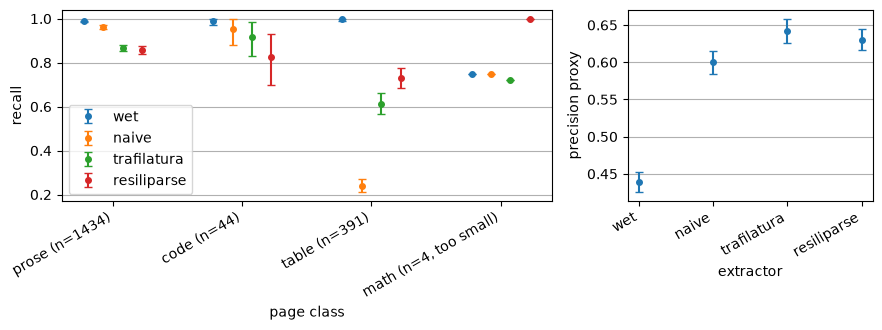

In [15]:
ev = [p for p in pages if p['html_lang'][0] == 'en'  # language of the HTML,
      and p['html_lang'][1] >= LID_MIN]             # not of any extractor
rows = []
for p in ev:
    dom = d2l.registered_domain(p['url'])
    for m in EXTRACTORS:  # a missing or empty output recalls nothing
        rows.append(dict(id=p['id'], domain=dom, extractor=m,
                         classes=p['struct']['classes'],
                         **d2l.structure_recall(p['struct'], p['texts'][m])))
rec = pd.DataFrame(rows)
in_c0 = sum(p['c0']['drop'] is None for p in ev)
print(f'{len(ev):,} pages English by their HTML ({in_c0:,} of them in c0);\n'
      'missing or empty output, scored 0: ' + ', '.join(
          f'{m} {sum(not p["texts"][m] for p in ev)}' for m in EXTRACTORS))

def interval(values, cluster, paired=None):
    """Mean with a 95% domain-clustered interval, or None (n too small)."""
    if len(values) < 30 or len(set(cluster)) < 30:
        return None
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        if paired is None:
            return d2l.bootstrap_ci(values, cluster=cluster)
        return d2l.paired_bootstrap(values, paired, cluster=cluster)

recall, deltas = [], []
for c in CLASSES:
    sub = rec[rec.classes.map(lambda cl: c in cl)]
    wide = sub.pivot(index='id', columns='extractor', values=c)
    doms = sub.drop_duplicates('id').set_index('id').domain
    for m in EXTRACTORS:
        v = wide[m].dropna()
        ci = interval(v.to_numpy(), doms[v.index].to_numpy())
        recall.append(dict(cls=c, extractor=m, n=len(v),
                           domains=doms[v.index].nunique(), mean=v.mean(),
                           lo=ci.ci[0] if ci else np.nan,
                           hi=ci.ci[1] if ci else np.nan))
    for a, b in [('trafilatura', 'resiliparse'), ('naive', 'trafilatura')]:
        both = wide[[a, b]].dropna()
        d = interval(both[a].to_numpy(), doms[both.index].to_numpy(),
                     paired=both[b].to_numpy())
        deltas.append(dict(cls=c, pair=f'{a} - {b}', n=len(both),
                           diff=both[a].mean() - both[b].mean(),
                           lo=d.ci[0] if d else np.nan,
                           hi=d.ci[1] if d else np.nan,
                           p=d.p_two_sided if d else np.nan))
recall, deltas = pd.DataFrame(recall), pd.DataFrame(deltas)
full = {p['id'] for p in ev  # pages where every extractor returned text
        if all(p['texts'][m] and p['texts'][m].strip() for m in EXTRACTORS)}
prec = []
for m in EXTRACTORS:
    v = rec[(rec.extractor == m) & rec.id.isin(full)].dropna(
        subset=['precision'])
    ci = interval(v.precision.to_numpy(), v.domain.to_numpy())
    prec.append(dict(extractor=m, n=len(v), mean=ci.mean, lo=ci.ci[0],
                     hi=ci.ci[1]))
prec = pd.DataFrame(prec)

fig, axes = d2l.plt.subplots(1, 2, figsize=(9, 3.4),
                             gridspec_kw=dict(width_ratios=[2, 1]))
shown = recall.assign(lo=recall.lo.fillna(recall['mean']),  # n too small:
                      hi=recall.hi.fillna(recall['mean']))  # no interval
ticks = []
for c in CLASSES:
    r = recall[(recall.cls == c) & (recall.extractor == 'trafilatura')]
    ticks.append(f'{c} (n={r.n.iloc[0]}'
                 + (', too small)' if r.lo.isna().iloc[0] else ')'))
d2l.plot_intervals(ticks, {m: tuple(
    shown[shown.extractor == m].set_index('cls').loc[CLASSES, k].to_numpy()
    for k in ('mean', 'lo', 'hi')) for m in EXTRACTORS},
    'page class', 'recall', axes=axes[0])
d2l.plot_intervals(EXTRACTORS, {'precision proxy': (prec['mean'], prec.lo,
                                                    prec.hi)},
                   'extractor', 'precision proxy', axes=axes[1])
fig.tight_layout()
print(deltas.round(3).to_string(index=False))

<!-- d2l:prose id=crawl-md-14 fw=all -->

The left panel shows recall by page class, and the extractors differ most
on tables. Resiliparse finds about 0.73 of the table cells and trafilatura
about 0.61, a paired difference of $-0.12$ with an interval from $-0.18$ to
$-0.06$. The naive extractor finds only 0.24, because cells are too short to
be blocks, as the fixture predicted. On prose the two libraries do not
differ: each recovers a little under 0.9 of the paragraph text, and the
paired interval includes 0. On code, 44 English pages are too few to
separate them. Mathematics we wanted to measure and could not, with 4
English pages from 2 domains. A general crawl is the wrong place to study
mathematical extraction; corpora such as FineMath start from pages selected
for it.

WET recalls nearly everything, since it keeps everything, and the right
panel shows what else it keeps. Its precision proxy is 0.44, against 0.60 to
0.64 for the three extractors, so more than half of WET's characters sit on
lines outside the content elements. The naive extractor is the surprise. It
keeps more paragraph text than either library, about 0.1 more, because it
has no notion of "the article" and keeps every dense paragraph, whether it
belongs to the article or not. It loses the tables, and its precision proxy
is the lowest of the three extractors. Between the two libraries the verdict
is clear for this sample: Resiliparse is at least as good as trafilatura
wherever we can tell them apart, and more than ten times faster.
Trafilatura's lead on code (0.92 against 0.82) is within the noise of 44
pages.

FineWeb's text for the same records offers a second view, and it must be
read carefully. It is not ground truth. FineWeb extracted it with
trafilatura, so agreement with it measures closeness to FineWeb's pipeline,
and an extractor that copied trafilatura's mistakes would score perfectly.
Even our trafilatura text is not FineWeb's. FineWeb ran trafilatura through
the datatrove library, whose defaults favor precision, remove repeated lines
and drop comments, while we call trafilatura with `favor_precision=False` and
its own defaults, which keep comments. FineWeb also replaced email addresses
and public IP addresses with fixed placeholders, so we mask addresses on both
sides before comparing; otherwise every scrubbed address would count as a
lost line. We join by record id, never by URL, because the same URL is
fetched again in later crawls, with different content.

In [16]:
by_id = {p['id']: p for p in pages}
in_range = fineweb[fineweb.url.isin(set(resp.url))]  # rows of the scanned part
ref, how = in_range.text[in_range.index.isin(list(by_id))], 'record id'
if len(ref) < 0.99 * len(in_range):  # fallback, a weaker match
    key = {(p['url'], p['c0']['row']['date']): p['id'] for p in pages}
    ref = pd.Series({key[(u, d)]: t for u, d, t in zip(
        in_range.url, in_range.date, in_range.text) if (u, d) in key})
    how = 'URL and date (weaker)'
joined = sorted(ref.index)  # our record ids of the pages FineWeb kept
print(f'{len(joined):,} of {len(in_range):,} FineWeb rows of this range '
      f'joined by {how}')
agree, masked = [], {}
for i in joined:
    p = by_id[i]
    cls = p['struct']['classes'] or ['none']
    for m in EXTRACTORS:  # a missing output (no WET record) is empty
        masked[i, m] = mask(p['texts'][m])
        prec_, rec_, f1 = d2l.char_ngram_f1(masked[i, m], mask(ref[i]))
        agree.append(dict(id=i, domain=d2l.registered_domain(p['url']),
                          extractor=m, cls=cls, f1=f1,
                          fineweb_only=1 - rec_, ours_only=1 - prec_))
agree = pd.DataFrame(agree)
summary = []
for m in EXTRACTORS:
    v = agree[agree.extractor == m]
    ci = interval(v.f1.to_numpy(), v.domain.to_numpy())
    summary.append(dict(extractor=m, n=len(v), f1=ci.mean, lo=ci.ci[0],
                        hi=ci.ci[1]))
summary = pd.DataFrame(summary)
print(summary.round(3).to_string(index=False))
split = (agree.explode('cls').groupby(['extractor', 'cls'])
         [['fineweb_only', 'ours_only']].mean().unstack('cls'))
print('\nshare of 5-grams only in FineWeb / only in ours, by page class:')
print(split.reindex(EXTRACTORS).round(2).to_string())
print('\nlines FineWeb kept and an extractor lost (FineWeb\'s text, ODC-By; '
      'addresses masked on both sides):')
for m in ['naive', 'resiliparse', 'trafilatura']:
    for i in joined:
        if not {'code', 'table'} & set(by_id[i]['struct']['classes']):
            continue
        out = d2l._ws(masked[i, m])
        lost = [l for l in mask(ref[i]).splitlines()
                if len(l) >= 40 and d2l._ws(l) not in out]
        if lost:
            print(textwrap.fill(f'{m}: {lost[0][:160]!r}', 96,
                                initial_indent='  ',
                                subsequent_indent='    '))
            break
print('(text: FineWeb, HuggingFaceFW/fineweb CC-MAIN-2025-05, ODC-By 1.0)')

1,002 of 1,002 FineWeb rows of this range joined by record id


  extractor    n    f1    lo    hi
        wet 1002 0.630 0.613 0.646
      naive 1002 0.783 0.768 0.798
trafilatura 1002 0.920 0.907 0.933
resiliparse 1002 0.763 0.745 0.781

share of 5-grams only in FineWeb / only in ours, by page class:
            fineweb_only                   ours_only                  
cls                 code  none prose table      code  none prose table
extractor                                                             
wet                 0.02  0.02  0.01  0.04      0.33  0.59  0.48  0.54
naive               0.07  0.07  0.03  0.09      0.26  0.37  0.27  0.40
trafilatura         0.01  0.11  0.02  0.06      0.18  0.15  0.08  0.14
resiliparse         0.05  0.18  0.08  0.14      0.21  0.38  0.27  0.42

lines FineWeb kept and an extractor lost (FineWeb's text, ODC-By; addresses masked on both sides):
  naive: 'Requires Android | Android 6.0+ (Marshmallow) |'
  resiliparse: 'Requires Android | Android 6.0+ (Marshmallow) |'
  trafilatura: 'Haigh Hall 4 Mile Race 

<!-- d2l:prose id=crawl-md-15 fw=all -->

All 1,002 FineWeb rows of the range join by record id. They are the pages
that FineWeb kept after all of its filters, about one HTML page in ten.
Trafilatura agrees with them best, at an F1 of 0.92; the naive extractor and
Resiliparse reach 0.76 to 0.78, and WET 0.63. The split by class says where
the disagreement lies: between a third and three fifths of WET's
five-character substrings, depending on the class, occur nowhere in
FineWeb's text, against 0.08 for trafilatura on prose pages. The lines
printed at the end are lines FineWeb kept and an extractor lost: a
row of an app's specification table, lost by both the naive extractor and
Resiliparse, and a line of an event listing, lost by our own trafilatura run.
Here is the reason never to read agreement as accuracy. Resiliparse recalled
more of the table text than trafilatura did, yet it agrees less with FineWeb,
because FineWeb's text is trafilatura's.

## Language Identification and Normalization

Pretraining corpora are split by language before anything else, because
every later rule, from quality filters to tokenizers, is tuned per language.
The standard tool is the language identifier of fastText (Joulin and
colleagues, 2017), which comes as a model of under 1 MB for 176 languages.
It is about as simple as a classifier can be. The text is cut into words and
their character n-grams, each is mapped to an embedding (the n-grams through
a hash table of fixed size), the embeddings are averaged, and a linear layer
with a softmax gives one score per language. Word order beyond the n-grams
is ignored, which is why it is fast enough to run on billions of pages.

The score is a softmax output, and it is tempting to read it as the
probability that a page is English. It is not. It is the model's preference
for English over 175 other labels, and a page that is half navigation, half
Python or half Spanish has no correct label among the 176. FineWeb keeps a
page if its top label is English with a score of at least 0.65, and so do
we. `detect_lang` replaces newlines by spaces first, since fastText reads a
single line.

In [17]:

_LID_MODEL = []  # the fastText model, loaded once per process


def detect_lang(text, k=1):
    """The top k (language, score) pairs of fastText's 176-language
    identifier (lid.176.ftz) for a text; newlines become spaces first, as
    fastText reads one line."""
    if not d2l._LID_MODEL:
        import fasttext
        fasttext.FastText.eprint = lambda *args, **kwargs: None  # quiet load
        d2l._LID_MODEL.append(fasttext.load_model(
            str(d2l.download_keyed('lid.176.ftz'))))
    labels, scores = d2l._LID_MODEL[0].predict(text.replace('\n', ' '), k=k)
    return [(l.removeprefix('__label__'), min(float(s), 1.0))
            for l, s in zip(labels, scores)]

<!-- d2l:prose id=crawl-md-16 fw=all -->

Common Crawl labels each WET record with the languages found by CLD2, the
compact language detector of the Chrome browser, so we can check one
identifier against another. The next cell crosses the two labels for the
eight most common languages. It then sweeps the English threshold from 0.5 to
0.9 and counts, at each value, the English documents we keep and how many of
those FineWeb kept. Three short strings at the end probe what a score is not.

fastText      en   zh   ru   ja   es   de   fr   pt  other
CLD2 (WET)                                                
en          3728   10   13   10   33   33   25   12     82
zh            25  741    0   10    1    0    4    0      7
ru             3    0  682    0    0    0    0    0      4
ja             5   40    0  483    0    0    0    0      0
es            13    0    0    0  465    0    0    5      2
de             5    0    0    0    0  404    2    0      2
fr             2    0    0    0    0    0  378    0      3
pt             2    0    0    0    1    0    0  214      0 

at 0.65: 3,288 English documents, 997 (30%) of them in FineWeb
sentence       [('en', 1.0), ('pl', 0.0)]
code comment   [('en', 0.98), ('vi', 0.0)]
code-switched  [('es', 0.9), ('gl', 0.06)]


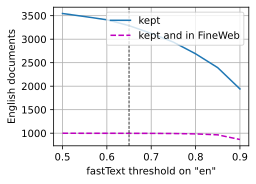

In [18]:
lid = {p['id']: d2l.detect_lang(p['texts']['trafilatura'])[0]
       for p in pages if p['texts']['trafilatura']}
assert all(lid[p['id']][0] == p['c0']['row']['lang'] and abs(
    lid[p['id']][1] - p['c0']['row']['lang_score']) < 1e-4
           for p in pages if p['id'] in lid)  # the workers agree
cld = {i: d2l._ISO639_3TO1.get(cld2[i].split(',')[0], cld2[i].split(',')[0]
                               or 'none') for i in lid if i in cld2}
top = [l for l, _ in collections.Counter(cld.values()).most_common(8)]
conf = pd.crosstab(pd.Series([cld[i] for i in cld], name='CLD2 (WET)'),
                   pd.Series([lid[i][0] if lid[i][0] in top else 'other'
                              for i in cld], name='fastText'))
print(conf.reindex(index=top, columns=top + ['other'], fill_value=0
                   ).to_string(), '\n')
en_scores = pd.Series({i: s for i, (l, s) in lid.items() if l == 'en'})
thresholds = np.round(np.arange(0.50, 0.91, 0.05), 2)
kept_en = [(en_scores >= t).sum() for t in thresholds]
in_fw = [en_scores[en_scores >= t].index.isin(joined).sum()
         for t in thresholds]
d2l.plot(thresholds, [kept_en, in_fw], 'fastText threshold on "en"',
         'English documents', legend=['kept', 'kept and in FineWeb'],
         legend_loc='upper right')
d2l.plt.axvline(LID_MIN, color='black', linestyle='--', linewidth=0.8)
k = list(thresholds).index(LID_MIN)
print(f'at {LID_MIN}: {kept_en[k]:,} English documents, {in_fw[k]:,} '
      f'({in_fw[k] / kept_en[k]:.0%}) of them in FineWeb')
for name, s in [
        ('sentence', 'The weather was cold so we stayed inside all day.'),
        ('code comment', 'x = load(path)  # The weather was cold so we '
                         'stayed inside all day\ny = x.sum()'),
        ('code-switched', 'The weather was cold, así que nos quedamos en '
                          'casa todo el día.')]:
    print(f'{name:14s}', [(l, round(sc, 2)) for l, sc in d2l.detect_lang(
        s, k=2)])

<!-- d2l:prose id=crawl-md-17 fw=all -->

The two identifiers mostly agree: the diagonal dominates for every language.
The largest disagreements are telling. On 40 pages CLD2 says Japanese and
fastText Chinese, which share many characters, and on 25 pages CLD2 says
Chinese and fastText English. On 82 pages that CLD2 calls English, fastText's
top label is a language outside the eight.

At the threshold of 0.65 we keep 3,288 English documents, and FineWeb kept
997 of them, about 30%. The rest fell to FineWeb's later stages, rules about
what a good document looks like and deduplication against the rest of the
crawl, the subjects of that section and
that section. The curve has a surprise of its own. Raising the
threshold from 0.5 to 0.8 removes 857 of our English documents, but only 14
of those FineWeb kept. A low language score tends to mark a page that the
later filters remove anyway. Only above 0.8
does the threshold start to cut pages that the full pipeline wanted.

The three strings show what a score is not. A plain English sentence scores
1.00. The same sentence as a comment in two lines of code still scores 0.98
for English: the identifier sees English words and ignores the code, and a
filter would call the snippet English prose. A sentence that switches from
English to Spanish halfway gets one label, Spanish, at 0.90. A score measures
confidence in the top label, not the share of the text written in that
language.

### Unicode Normalization

The same visible text can be different sequences of code points. The letter
é is one code point, U+00E9, or two, `e` followed by the combining acute
accent U+0301, and a page may use either. Unicode defines *normalization
forms* that map such equivalent sequences to one representative (Unicode
Standard Annex 15). NFC composes canonically equivalent sequences: é becomes
one code point, Korean jamo become syllables, and nothing on the screen
changes. NFKC goes further and also maps *compatibility* characters to plain
ones: the ligature ﬁ to `fi`, the superscript of x² to `2`, the mathematical
italic 𝑥 to `x`, full-width letters to ASCII. It reads like a cleanup, and
that is its danger. Once x² has become x2, a formula or a variable name means
something else.

Why normalize at all? Recall from that section that a
byte-level tokenizer sees the UTF-8 bytes of a text, not its characters. A
composed é is two bytes, `C3 A9`, and a decomposed one three, `65 CC 81`, so
two documents that look identical give different token sequences.
Bits per byte, the measure this chapter uses to compare data mixtures and
tokenizers, would then be computed over different byte counts for the same
text. The rule this book follows is short: apply NFC once, to every document,
before any tokenizer sees it, and count bytes after it. The next cell
measures what NFC and NFKC would change in the English documents of our
range.

In [19]:
en = [p for p in pages if p['c0']['drop'] is None]  # the c0 documents
docs_en = [p['texts']['trafilatura'] for p in en]
loss, changed = {}, {}
for form in ('NFC', 'NFKC'):
    changed[form] = [s for s in docs_en
                     if not unicodedata.is_normalized(form, s)]
    loss[form] = dict(  # code points: those the form maps on their own
        documents_changed=len(changed[form]),
        share=len(changed[form]) / len(docs_en),
        code_points_rewritten=sum(unicodedata.normalize(form, c) != c
                                  for s in changed[form] for c in s),
        length_change=sum(len(unicodedata.normalize(form, s)) - len(s)
                          for s in changed[form]))
print(pd.DataFrame(loss).T.round(3).to_string(), '\n')
nfkc = collections.Counter(c for s in changed['NFKC'] for c in s
                           if unicodedata.normalize('NFKC', c) != c)
print(pd.DataFrame([dict(
    code_point=f'U+{ord(c):04X} {unicodedata.name(c, "?")}',
    nfkc=repr(unicodedata.normalize('NFKC', c)), count=n,
    category=unicodedata.category(c)) for c, n in nfkc.most_common(10)]
    ).to_string(index=False), '\n')
nfc = lambda s: unicodedata.normalize('NFC', s)
assert all(nfc(nfc(s)) == nfc(s) for s in docs_en)  # NFC is idempotent
for name, ch in [('U+FFFD replacement', '�'), ('U+00A0 NBSP', '\xa0'),
                 ('U+200B zero-width space', '​'),
                 ('U+200D zero-width joiner', '‍'),
                 ('U+FEFF byte-order mark', '﻿')]:
    print(f'{name:26s} in {sum(ch in s for s in docs_en):5,} documents, '
          f'{sum(s.count(ch) for s in docs_en):7,} times')

      documents_changed  share  code_points_rewritten  length_change
NFC                 0.0  0.000                    0.0            0.0
NFKC              619.0  0.188                 7911.0         2298.0 

                        code_point  nfkc  count category
             U+00A0 NO-BREAK SPACE   ' '   6245       Zs
        U+2026 HORIZONTAL ELLIPSIS '...'    949       Po
               U+2033 DOUBLE PRIME  '′′'    200       Po
            U+2122 TRADE MARK SIGN  'TM'    103       So
            U+FF1A FULLWIDTH COLON   ':'     71       Po
            U+FF0C FULLWIDTH COMMA   ','     29       Po
   U+00BD VULGAR FRACTION ONE HALF '1⁄2'     15       No
U+00BC VULGAR FRACTION ONE QUARTER '1⁄4'     13       No
 U+1D41A MATHEMATICAL BOLD SMALL A   'a'     11       Ll
 U+1D422 MATHEMATICAL BOLD SMALL I   'i'     11       Ll 



U+FFFD replacement         in     6 documents,      18 times
U+00A0 NBSP                in   292 documents,   6,245 times
U+200B zero-width space    in     0 documents,       0 times
U+200D zero-width joiner   in     0 documents,       0 times
U+FEFF byte-order mark     in     0 documents,       0 times


<!-- d2l:prose id=crawl-md-18 fw=all -->

NFC changes none of the 3,288 documents (and applying it twice changes
nothing, as the assertion checks): the English text of this range is
already composed. NFKC
changes 619 of them, 19%, rewriting 7,911 code points. Most of the rewrites
are harmless. No-break spaces become spaces and the ellipsis becomes three
dots. Further down the list they are not. The double prime of inches and
arc-seconds becomes two primes, ™ becomes the letters TM, and full-width
colons and commas in Chinese text become ASCII punctuation. ½ and ¼ become
digits around a fraction slash, and mathematical bold letters become plain
ones, erasing what may be the only mark of a vector. No-break spaces occur in 292
documents, and 6 documents still carry U+FFFD, decoding failures that the
charset chain did not catch. This sample has no zero-width joiners, but a
multilingual corpus does, and there they matter: in Devanagari the joiner
selects a half-form of a consonant, and in emoji it joins a family into one
symbol. A rule that strips "invisible" characters changes those texts. NFC,
and nothing else, is the normalization of this chapter.

## Personal Data, Rights and the Manifest

A crawl holds whatever people have put on public pages: their email
addresses, phone numbers and home addresses, and, in forum threads, their
health. A corpus repeats it, and a language model can memorize and reproduce
text it has seen several times. Some of it can be removed by rule. An email
address has a fixed shape, and so has an IP address, which can identify a
household. FineWeb replaces both with placeholders, and so does `scrub_pii`,
which parses every candidate IP address and keeps private, loopback,
documentation and multicast addresses (192.168.1.1 identifies nobody). Names,
street addresses and a sentence about someone's diagnosis have no fixed
shape. No regular expression finds them, and model-based detectors find some
of them along with many false alarms. We implement what rules can do,
and it is the easy part.

In [20]:

PII_PATTERNS = {
    'email': re.compile(r'\b[A-Za-z0-9._%+-]+@(?:[A-Za-z0-9-]+\.)+'
                        r'[A-Za-z]{2,}\b'),
    'ip': re.compile(r'(?<![\w.:])(?:(?:\d{1,3}\.){3}\d{1,3}|'
                     r'(?:[0-9A-Fa-f]{1,4}:){7}[0-9A-Fa-f]{1,4}|'
                     r'(?:[0-9A-Fa-f]{1,4}:){1,6}:'
                     r'(?:[0-9A-Fa-f]{1,4}:){0,5}[0-9A-Fa-f]{1,4})'
                     r'(?![\w:]|\.\d)')}  # a sentence may end in a dot


def scrub_pii(text):
    """Replace email addresses by <EMAIL> and public IPv4 and IPv6
    addresses by <IP> (an address must parse; private, loopback,
    documentation and multicast ranges are kept); returns the text and
    the counts."""
    import ipaddress
    counts = {'email': 0, 'ip': 0}

    def email(m):
        counts['email'] += 1
        return '<EMAIL>'

    def ip(m):
        try:
            a = ipaddress.ip_address(m.group())
            public = a.is_global and not a.is_multicast
        except ValueError:
            return m.group()
        counts['ip'] += public
        return '<IP>' if public else m.group()

    text = d2l.PII_PATTERNS['email'].sub(email, text)
    return d2l.PII_PATTERNS['ip'].sub(ip, text), counts

<!-- d2l:prose id=crawl-md-19 fw=all -->

How good are two regular expressions? The fixture below holds 60 strings with
an address and 60 without, many of the latter chosen to look like one. We
wrote it together with the rules (the case of an address at the end of a
sentence came from it), so it is a specification of what the rules match and
miss, not an estimate of their accuracy on web text. Its recall of 1.0 holds
by construction.

In [21]:

PII_FIXTURE = [  # (string, kind it holds: 'email', 'ip' or None)
    ('write to anna.berg@example.org for the slides', 'email'),
    ('Contact: j.smith+news@mail.example.co.uk', 'email'),
    ('send it to OPS@EXAMPLE.COM today', 'email'),
    ('reach me at li_wei99@uni-example.edu.cn', 'email'),
    ('Fragen an info@beispiel.de bitte', 'email'),
    ('(maria.garcia@correo.example.es)', 'email'),
    ('mailto:help-desk@example.net', 'email'),
    ('cc: bob@sub.domain.example.io, alice@example.ai', 'email'),
    ('Author: k.tanaka@example.jp', 'email'),
    ('reply to noreply@notifications.example.com', 'email'),
    ('email: first.last@company-example.com.', 'email'),
    ('<a href="mailto:press@example.org">press</a>', 'email'),
    ('orders: sales@shop.example.store', 'email'),
    ('my address is pat_2001@example.travel', 'email'),
    ('Ping x@example.dev if the build breaks', 'email'),
    ('Webmaster - webmaster@example.museum', 'email'),
    ('send CVs to jobs@example.careers', 'email'),
    ('Report abuse: abuse@isp.example.net', 'email'),
    ('questions -> q.and.a@forum.example.org', 'email'),
    ('Kontakt: m.mueller@firma-beispiel.at', 'email'),
    ('his email (tom.o@example.ie) was on the poster', 'email'),
    ('chair: prof.chen@cs.example.edu', 'email'),
    ('Email:support@example.com', 'email'),
    ('a.b.c.d@example.co', 'email'),
    ('Subscribe: list-request@lists.example.org', 'email'),
    ('billing@example.biz handles refunds', 'email'),
    ('user%host@example.com is an old relay form', 'email'),
    ('Send photos to editor@news.example.com.au', 'email'),
    ('Tel. 555-0100, mail: office@example.fr', 'email'),
    ('Questions? Ask ivan.petrov@example.ru', 'email'),
    ('server at 8.8.8.8 answered', 'ip'),
    ('Client IP: 203.0.114.7', 'ip'),
    ('ssh root@93.184.216.34', 'ip'),
    ('blocked 45.33.32.156 after 5 tries', 'ip'),
    ('origin=151.101.1.69;', 'ip'),
    ('ping 1.1.1.1 -c 4', 'ip'),
    ('from host 81.2.69.160 port 443', 'ip'),
    ('X-Forwarded-For: 66.249.66.1', 'ip'),
    ('the attack came from 185.220.101.4.', 'ip'),
    ('[23.45.67.89]', 'ip'),
    ('IP 104.16.132.229 resolved', 'ip'),
    ('nameserver 9.9.9.9', 'ip'),
    ('allowlist: 52.95.110.1', 'ip'),
    ('log line 17.253.144.10 - - [26/Jan/2025]', 'ip'),
    ('192.30.255.112 is listed', 'ip'),
    ('visit http://200.147.67.142/index', 'ip'),
    ('my VPS is 139.59.21.43', 'ip'),
    ('peer: 77.88.55.60', 'ip'),
    ('gateway (31.13.71.36)', 'ip'),
    ('upstream 140.82.112.3', 'ip'),
    ('AAAA 2a00:1450:4001:82a::200e', 'ip'),
    ('v6: 2606:4700:4700::1111', 'ip'),
    ('host 2620:fe::fe answers', 'ip'),
    ('2a03:2880:f12f:83:face:b00c:0:25de', 'ip'),
    ('from 2001:4860:4860::8888', 'ip'),
    ('addr 2a01:4f8:c17:1234::1', 'ip'),
    ('[2400:cb00:2048:1::c629:d7a2]', 'ip'),
    ('client 2a02:6b8::2:242 connected', 'ip'),
    ('route via 2600:1f18:6a3:4b00::12', 'ip'),
    ('ns 2001:500:2f::f', 'ip'),
    ('our router is at 192.168.1.1', None),
    ('the cluster uses 10.0.0.0/8 internally', None),
    ('localhost is 127.0.0.1', None),
    ('documentation range 192.0.2.15', None),
    ('link-local fe80::1ff:fe23:4567:890a', None),
    ('test net 198.51.100.7', None),
    ('private 172.16.254.3', None),
    ('loopback ::1 only', None),
    ('unique local fd12:3456:789a:1::1', None),
    ('example 2001:db8::ff00:42:8329', None),
    ('Upgrade to version 4.2.1.0 now', None),
    ('Changelog for 1.2.3.4 (stable)', None),
    ('build 5.15.0.91 of the kernel', None),
    ('SNMP OID 1.3.6.1.4.1.2021', None),
    ('section 3.4.1.2 of the standard', None),
    ('ISBN 978-0-306-40615-7', None),
    ('ISBN 0-306-40615-2 (paperback)', None),
    ('phone +1 555 0100 222', None),
    ('the score was 3.14.15.92 in the puzzle', None),
    ('logo@2x.png in the assets folder', None),
    ('icon@3x.webp for retina screens', None),
    ('follow @d2l_ai for updates', None),
    ('write to anna dot berg at example dot org', None),
    ('the domain example.com hosts it', None),
    ('price 1.299,00 EUR', None),
    ('coordinates 52.5200, 13.4050', None),
    ('date 2025.01.26', None),
    ('time 13:54:02', None),
    ('MAC 00:1A:2B:3C:4D:5E', None),
    ('C++ uses std::vector<int>', None),
    ('the ratio 16:9 screen', None),
    ('PEP 8 says @decorator first', None),
    ('the user name is root', None),
    ('256.300.1.2 is not an address', None),
    ('999.1.1.1 overflows', None),
    ('vector 1:2:3 notation', None),
    ('npm i pkg@1.2.3', None),
    ('git@github.com:org/repo.git', None),
    ('the hash a3f2:9c1e', None),
    ('Bible verse John 3:16', None),
    ('temperature 21.5 C', None),
    ('a.b@c', None),
    ('foo@bar', None),
    ('10.10.10.10 on the lab switch', None),
    ('the meeting is at 10.30', None),
    ('patent US 7,654,321 B2', None),
    ('IPv4 has 4.3 billion addresses', None),
    ('the CIDR 0.0.0.0/0 means everything', None),
    ('multicast 224.0.0.251 for mDNS', None),
    ('broadcast 255.255.255.255', None),
    ('shared address space 100.64.0.1', None),
    ('benchmark range 198.18.0.1', None),
    ('version v2.0.0.1-beta', None),
    ('model 7.1.2.3 of the router firmware', None),
    ('ISSN 0317-8471', None),
    ('the regex \\d+@\\w+', None),
    ('emoji :smile: in chat', None),
    ('call 0800 123 4567 for help', None),
    ('IBAN DE89 3704 0044 0532 0130 00', None),
    ('ISBN-13 978.3.16.148410.0', None)]

kinds = ['email', 'ip']
pred = [d2l.scrub_pii(s)[1] for s, _ in d2l.PII_FIXTURE]
table = []
for k in kinds:
    tp = sum(p[k] > 0 and t == k for p, (_, t) in zip(pred, d2l.PII_FIXTURE))
    fp = sum(p[k] > 0 and t != k for p, (_, t) in zip(pred, d2l.PII_FIXTURE))
    pos = sum(t == k for _, t in d2l.PII_FIXTURE)
    table.append(dict(pattern=k, positives=pos, recall=tp / pos,
                      precision=tp / max(tp + fp, 1), false_positives=fp))
print(f'{len(d2l.PII_FIXTURE)} fixture strings, '
      f'{sum(t is not None for _, t in d2l.PII_FIXTURE)} with personal data')
print(pd.DataFrame(table).round(3).to_string(index=False))
print('false positives:')
for hits, (fixture, kind) in zip(pred, d2l.PII_FIXTURE):
    if kind is None and any(hits.values()):
        print(f'  {fixture!r}')
scrub = [d2l.scrub_pii(unicodedata.normalize('NFC', p['texts']['trafilatura']))
         for p in en]
assert all(c == p['c0']['pii'] for (_, c), p in zip(scrub, en))
n_email = sum(c['email'] > 0 for _, c in scrub)
n_ip = sum(c['ip'] > 0 for _, c in scrub)
delta = sum(len(t.encode()) - len(unicodedata.normalize(
    'NFC', p['texts']['trafilatura']).encode())
            for (t, _), p in zip(scrub, en))
print(f'c0 ({len(en):,} English documents), rule matches (not checked by '
      f'hand):\n  emails in {n_email} documents, public IP addresses in '
      f'{n_ip};\n  {sum(c["email"] for _, c in scrub)} and '
      f'{sum(c["ip"] for _, c in scrub)} replaced; UTF-8 bytes changed by '
      f'{delta:+,}')

120 fixture strings, 60 with personal data
pattern  positives  recall  precision  false_positives
  email         30     1.0      0.909                3
     ip         30     1.0      0.833                6
false positives:
  'Upgrade to version 4.2.1.0 now'
  'Changelog for 1.2.3.4 (stable)'
  'build 5.15.0.91 of the kernel'
  'section 3.4.1.2 of the standard'
  'the score was 3.14.15.92 in the puzzle'
  'logo@2x.png in the assets folder'
  'icon@3x.webp for retina screens'
  'git@github.com:org/repo.git'
  'model 7.1.2.3 of the router firmware'


c0 (3,288 English documents), rule matches (not checked by hand):
  emails in 173 documents, public IP addresses in 8;
  421 and 27 replaced; UTF-8 bytes changed by -6,625


<!-- d2l:prose id=crawl-md-20 fw=all -->

The false positives are the interesting output. Four numbers below 256
joined by dots parse as an address, and most such addresses are public, so
version numbers, a kernel build, the section number of a standard and a
puzzle score are all replaced. The
names `logo@2x.png` and `icon@3x.webp`, which web designers give to images
for high-resolution screens, look like email addresses, and so does the git
address `git@github.com:org/repo.git`. Every one of them is code or
documentation, exactly the text a model should learn character for
character. On the 3,288 documents the rules match emails in 173 documents
(421 replacements) and public IP addresses in 8 (27 replacements); these are
rule matches, not checked by hand. The replacements shorten the corpus by
6,625 UTF-8 bytes, one more reason to scrub before bytes are counted.

Personal data is one kind of right attached to a page; copyright and the
site's terms are others. Common Crawl is an archive. It honors `robots.txt`
when it crawls, but it grants no licence for what it stores, and a page's
being public does not make its text free to copy. Site owners have noticed.
*Consent in Crisis* (Longpre and colleagues, 2024) audited the `robots.txt`
files and terms of service behind widely used corpora. Restrictions aimed at
AI crawlers spread within a single year, most of all among the actively
maintained sites that supply much of the useful text.

Rights therefore enter a pipeline as engineering inputs, like any other
field. Each of our documents records where it came from: the WARC file, the
byte offset and length of its record, the URL and the fetch date. A licence
field, an opt-out list checked at build time and a log of removals make a
request enforceable. The Stack v2 (Lozhkov and colleagues, 2024), a corpus of
source code, records the licence of every file and removes the repositories
of developers who opt out before each release. With byte offsets in every
row, a takedown request is the deletion of one row, and the next rebuild no
longer contains the page. This book applies the same rule to itself: it
publishes no text extracted from the crawl, only pins, ids, offsets and
hashes, and the notebook rebuilds the text from Common Crawl's servers. The
crawl text it prints is FineWeb's, released by its authors under ODC-By.
None of this is legal advice; the law differs between countries and is
changing.

Everything in this section was English, and that was a choice, not a
necessity. FineWeb-2 (Penedo and colleagues, 2025) runs a pipeline of the
same shape over Common Crawl for more than a thousand languages and finds
that rules tuned for English fail elsewhere. Its language identifier covers
far more languages than fastText's 176, its thresholds are set per language
from the distribution of scores, and its filters and deduplication are
adjusted per language as well. Its per-language pages return in
that section, where one tokenizer meets ten languages.

### The Manifest

Every number in this section came from a decision: which bytes, which
charset, which extractor at which version, which threshold. A corpus that
does not record its decisions cannot be rebuilt, audited or corrected after a
takedown. We record them at two levels. Each document is a `d2l.Doc` holding
its text, id, URL, date, language and score, its source (`src`: the WARC
file, offset and length) and a log of what was done to it. The corpus as a
whole is described by a *manifest*, a JSON file in the schema
`d2l-corpus/1` (the table), which the rest of
the chapter extends: filters in that section,
deduplication in that section, and the tokenizer, shard format and
splits in that section.

<!-- tbl-caption:The corpus manifest, schema `d2l-corpus/1`. This section fills the sources and four stages; later sections add stages and the last three fields. -->

| field | holds | example in this section |
|:--|:--|:--|
| `schema`, `name` | the schema version and the corpus name | `d2l-corpus/1`, `c0` |
| `sources[]` | `id`, `uri`, `revision` (a content hash or commit), `license`, `n_docs`, `bytes` | the WARC file, its SHA-256, 9,731 responses, 268,435,456 bytes |
| `stages[]` | `name`, `impl`, `version`, `params`, `n_in`, `n_out`, `drops` (reason: count), `in_hash`, `out_hash`, `tokens_out` | `extract` with trafilatura 2.1.0; `lang_id` with `min_score` 0.65 |
| `tokenizer` | file, SHA-256, vocabulary size, special tokens | empty until that section |
| `format` | token dtype, end-of-document id, byte order | empty until that section |
| `splits` | per split: documents, tokens and shard files with their hashes | empty until that section |

The documents are written as gzip-compressed JSON lines with sorted keys and
no time stamp in the gzip header, so equal documents give equal bytes.

In [22]:

Doc = collections.namedtuple(
    'Doc', 'id url date text lang lang_score src log flags')


def write_docs(path, docs):
    """Write documents (Doc or dicts with Doc's fields) as gzip-compressed
    JSON lines, keys sorted and no time stamp in the gzip header, so equal
    documents give equal bytes."""
    with open(path, 'wb') as raw, gzip.GzipFile(
            filename='', mode='wb', fileobj=raw, mtime=0) as f:
        for d in docs:
            row = d._asdict() if hasattr(d, '_asdict') else dict(d)
            f.write((json.dumps(row, ensure_ascii=False, sort_keys=True)
                     + '\n').encode('utf-8'))


def read_docs(path):
    """The documents of a file written by write_docs, as a list of Doc
    (fields missing from a row are None)."""
    with gzip.open(path, 'rt', encoding='utf-8') as f:
        rows = [json.loads(line) for line in f]
    return [d2l.Doc(**{k: r.get(k) for k in d2l.Doc._fields}) for r in rows]


def docs_hash(docs):
    """SHA-256 over the sorted (id, SHA-256 of the text) pairs: the content
    of a document set, independent of its order. Takes Doc-like objects,
    dicts or (id, text) pairs."""
    def pair(d):
        if isinstance(d, dict):
            return d['id'], d['text']
        if hasattr(d, 'text'):
            return d.id, d.text
        return d[0], d[1]
    keys = sorted((str(i), hashlib.sha256((t or '').encode('utf-8'))
                   .hexdigest()) for i, t in map(pair, docs))
    h = hashlib.sha256()
    for i, t in keys:
        h.update(f'{i}\t{t}\n'.encode('utf-8'))
    return h.hexdigest()

<!-- d2l:prose id=crawl-md-21 fw=all -->

Two rules make a manifest checkable. First, every stage balances: each
document that enters either leaves or is charged to exactly one reason for
dropping it,

$$n_\textrm{in} = n_\textrm{out} + \sum_r \textrm{drops}_r,$$

and a document that several rules would drop is charged to the first of them
in the stage's order. The order is therefore a parameter of the stage, since
it changes the counts. Second, the manifest has one canonical byte form:
sorted keys, no spaces, floats rounded to four decimals, no time stamps and
no absolute paths. Its SHA-256 then names the corpus, and two builds that
made the same decisions produce the same hash on any machine. A time stamp or
a path such as `/home/user/data` would make every build unique and the hash
useless, which is why `canonical_json` refuses absolute paths. The content of
a set of documents has a hash of its own, `docs_hash`: the SHA-256 over the
sorted pairs of document id and text hash. It ignores the order of the
documents and changes with any byte of any text.

In [23]:

class CorpusManifest:
    """The provenance of a corpus (schema d2l-corpus/1): its sources, the
    stages that turned them into documents, and, once tokenized, the
    tokenizer, the shard format and the splits. Each stage satisfies
    n_in == n_out + sum(drops), a document being charged to the first rule
    that drops it. The canonical JSON has sorted keys, no spaces, floats
    rounded to 4 decimals and no absolute paths; sha256() hashes it."""
    SCHEMA = 'd2l-corpus/1'

    def __init__(self, name, sources=None, stages=None, tokenizer=None,
                 format=None, splits=None):
        self.name, self.tokenizer, self.format = name, tokenizer, format
        self.sources, self.stages = list(sources or []), list(stages or [])
        self.splits = splits

    def add_source(self, id, uri, revision=None, license=None, n_docs=None,
                   bytes=None, **extra):
        self.sources.append(dict(id=id, uri=uri, revision=revision,
                                 license=license, n_docs=n_docs,
                                 bytes=bytes, **extra))
        return self

    def add_stage(self, name, params, n_in, n_out, drops, in_hash, out_hash,
                  *, impl=None, version=None, tokens_out=None):
        drops = {str(k): int(v) for k, v in (drops or {}).items()}
        if n_in != n_out + sum(drops.values()):
            raise ValueError(f'stage {name}: n_in {n_in} != n_out {n_out} '
                             f'+ drops {sum(drops.values())}')
        self.stages.append(dict(
            name=name, impl=impl, version=version, params=params,
            n_in=int(n_in), n_out=int(n_out), tokens_out=tokens_out,
            drops=drops, in_hash=in_hash, out_hash=out_hash))
        return self

    def to_dict(self):
        return dict(schema=self.SCHEMA, name=self.name, sources=self.sources,
                    stages=self.stages, tokenizer=self.tokenizer,
                    format=self.format, splits=self.splits)

    def canonical_json(self):
        def clean(x, where):
            if isinstance(x, float):
                if x != x or x in (float('inf'), float('-inf')):
                    raise ValueError(f'{where}: {x} has no JSON form')
                return round(x, 4)
            if isinstance(x, (np.integer, np.floating, np.bool_)):
                return clean(x.item(), where)
            if isinstance(x, str) and (x.startswith('/') or
                                       re.match(r'[A-Za-z]:\\', x)):
                raise ValueError(f'{where}: absolute path {x!r}')
            if isinstance(x, dict):
                return {str(k): clean(v, f'{where}.{k}')
                        for k, v in x.items()}
            if isinstance(x, (list, tuple)):
                return [clean(v, f'{where}[{i}]') for i, v in enumerate(x)]
            return x
        return json.dumps(clean(self.to_dict(), 'manifest'), sort_keys=True,
                          separators=(',', ':'), ensure_ascii=False)

    def sha256(self):
        return hashlib.sha256(self.canonical_json().encode('utf-8')
                              ).hexdigest()

    def save(self, path):
        """Write the canonical JSON, so the file's SHA-256 is sha256()."""
        with open(path, 'wb') as f:
            f.write(self.canonical_json().encode('utf-8'))
        return path

    @classmethod
    def load(cls, path):
        with open(path, encoding='utf-8') as f:
            d = json.load(f)
        if d.get('schema') != cls.SCHEMA:
            raise ValueError(f'{path}: schema {d.get("schema")!r}, '
                             f'expected {cls.SCHEMA}')
        return cls(d['name'], d.get('sources'), d.get('stages'),
                   d.get('tokenizer'), d.get('format'), d.get('splits'))

    def to_card(self):
        """A Markdown dataset card generated from the manifest alone."""
        lines = [f'# Dataset card: {self.name}', '',
                 f'Schema `{self.SCHEMA}`, manifest SHA-256 '
                 f'`{self.sha256()[:16]}…`.', '', '## Sources', '',
                 '| id | uri | revision | license | documents | bytes |',
                 '|---|---|---|---|---|---|']
        for s in self.sources:
            lines.append('| ' + ' | '.join(str(s.get(k, '')) for k in (
                'id', 'uri', 'revision', 'license', 'n_docs', 'bytes')) + ' |')
        lines += ['', '## Processing stages', '',
                  '| stage | implementation | in | out | dropped (reason: count) |',
                  '|---|---|---|---|---|']
        for s in self.stages:
            impl = ' '.join(str(v) for v in (s.get('impl'), s.get('version'))
                            if v)
            drops = ', '.join(f'{k}: {v}' for k, v in s['drops'].items()
                              ) or '—'
            lines.append(f'| {s["name"]} | {impl or "—"} | {s["n_in"]} | '
                         f'{s["n_out"]} | {drops} |')
        if self.tokenizer:
            lines += ['', '## Tokenizer', '', '```',
                      json.dumps(self.tokenizer, sort_keys=True), '```']
        if self.format:
            lines += ['', '## Format', '', '```',
                      json.dumps(self.format, sort_keys=True), '```']
        if self.splits:
            lines += ['', '## Splits', '', '| split | documents | tokens | shards |',
                      '|---|---|---|---|']
            for k, v in sorted(self.splits.items()):
                lines.append(f'| {k} | {v.get("n_docs")} | {v.get("n_tokens")}'
                             f' | {len(v.get("shards", []))} |')
        return '\n'.join(lines) + '\n'

<!-- d2l:prose id=crawl-md-22 fw=all -->

We now write the manifest of *c0*, the chapter's first corpus: the English
documents of the range after extraction with trafilatura (FineWeb's
extractor), language identification at FineWeb's threshold, NFC and the
scrubbing of addresses. The cell then tests the hashes. The manifest must
survive a save and a load, and the document hash must survive a permutation
of the documents and change when one character of one document changes.

In [24]:
with open(d2l.download_keyed('lm-cc-warc-256m-v1')) as f:
    pin = json.load(f)
resp = index[index.type == 'response']
c0 = {p['id']: p['c0'] for p in pages}
empty = [i for i, o in c0.items() if o['drop'] == 'empty']
nonempty = [p for p in pages if c0[p['id']]['drop'] != 'empty']
kept = [p for p in nonempty if c0[p['id']]['drop'] is None]
raw = lambda ps: [(p['id'], p['texts']['trafilatura']) for p in ps]
nfc_docs = [(p['id'], unicodedata.normalize('NFC', p['texts']['trafilatura']))
            for p in kept]
docs = [d2l.Doc(o['row']['id'], o['row']['url'], o['row']['date'], o['text'],
                o['row']['lang'], o['row']['lang_score'], o['row']['src'],
                o['row']['log'], None) for o in (c0[p['id']] for p in kept)]
m = d2l.CorpusManifest('c0')
m.add_source('cc-main-2025-05-00000', pin['warc']['url'],
             revision=pin['warc']['sha256'], n_docs=len(resp),
             bytes=CRAWL_MIB * 2**20, license='none granted (Common Crawl '
             'terms of use); text not redistributed')
m.add_stage('extract', dict(rules=['not_200', 'not_html', 'empty'],
                            charset_chain=['header', 'meta', 'detector',
                                           'fallback'],
                            include_tables=True, favor_precision=False,
                            versions={k: importlib.metadata.version(k) for k in
                                      ('lxml', 'justext', 'charset-normalizer')}),
            len(resp), len(nonempty), dict(
                not_200=int((resp.status != 200).sum()),
                not_html=int(((resp.status == 200) &
                              (resp.mime != 'text/html')).sum()),
                empty=len(empty)), pin['warc']['sha256'],
            d2l.docs_hash(raw(nonempty)), impl='trafilatura',
            version=importlib.metadata.version('trafilatura'))
m.add_stage('lang_id', dict(rules=['not_en', 'low_score'], label='en',
                            min_score=LID_MIN, model='lid.176.ftz',
                            model_sha1=d2l.DATA_HUB['lid.176.ftz'][1]),
            len(nonempty), len(kept), collections.Counter(
                c0[p['id']]['drop'] for p in nonempty if c0[p['id']]['drop']),
            d2l.docs_hash(raw(nonempty)), d2l.docs_hash(raw(kept)),
            impl='fasttext',
            version=importlib.metadata.version('fasttext-numpy2-wheel'))
m.add_stage('nfc', dict(form='NFC'), len(kept), len(kept), {},
            d2l.docs_hash(raw(kept)), d2l.docs_hash(nfc_docs),
            impl='unicodedata', version=unicodedata.unidata_version)
m.add_stage('pii', dict(patterns=sorted(d2l.PII_PATTERNS),
                        replace=dict(email='<EMAIL>', ip='<IP>')),
            len(kept), len(docs), {}, d2l.docs_hash(nfc_docs),
            d2l.docs_hash(docs), impl='d2l.scrub_pii')
print(pd.DataFrame([dict(stage=s['name'], n_in=s['n_in'], n_out=s['n_out'],
                         dropped=', '.join(f'{k} {v:,}' for k, v in
                                           s['drops'].items()) or '-')
                    for s in m.stages]).to_string(index=False))

cache = os.path.join('..', 'data', 'lm', 'c0')
os.makedirs(cache, exist_ok=True)
m.save(os.path.join(cache, 'c0-manifest.json'))
again = d2l.CorpusManifest.load(os.path.join(cache, 'c0-manifest.json'))
order = np.random.default_rng(0).permutation(len(docs))
last = docs[1].text[-1]
edited = docs[:1] + [docs[1]._replace(  # one character changed
    text=docs[1].text[:-1] + ('#' if last != '#' else '%'))] + docs[2:]
print(f'manifest {m.sha256()[:16]}…, after save and load '
      f'{again.sha256()[:16]}…;\ndocs_hash {d2l.docs_hash(docs)[:16]}…, '
      f'permuted {d2l.docs_hash([docs[i] for i in order])[:16]}…, '
      f'one byte edited {d2l.docs_hash(edited)[:16]}…')
assert again.sha256() == m.sha256()
assert d2l.docs_hash([docs[i] for i in order]) == d2l.docs_hash(docs)
assert d2l.docs_hash(edited) != d2l.docs_hash(docs)

rows = [c0[p['id']]['row'] for p in kept]  # WARC order, no text
C0_KEY, C0_FILE = ARTIFACTS['c0']
if 'c0' in RERUN:
    d2l.lm_save_rerun(C0_FILE, lambda f: d2l.write_docs(f, rows))
else:
    with gzip.open(d2l.lm_artifact(C0_KEY), 'rt', encoding='utf-8') as f:
        reg = [json.loads(line) for line in f]
    same = [(r['id'], r['text_sha256']) for r in reg] == [
        (r['id'], r['text_sha256']) for r in rows]
    print(f'against {C0_KEY}: {len(reg):,} registered rows, {len(rows):,} '
          f'now; ids and text hashes {"identical" if same else "DIFFER"}')
    assert same

  stage  n_in  n_out                            dropped
extract  9731   9286 not_200 0, not_html 140, empty 305
lang_id  9286   3288        not_en 5,448, low_score 550
    nfc  3288   3288                                  -
    pii  3288   3288                                  -
manifest 45a63f710b73643e…, after save and load 45a63f710b73643e…;
docs_hash 803e7466effd8553…, permuted 803e7466effd8553…, one byte edited 6100ba91b6143c7a…
against lm-c0-docs-v1: 3,288 registered rows, 3,288 now; ids and text hashes identical


<!-- d2l:prose id=crawl-md-23 fw=all -->

The funnel is steep. Of 9,731 responses, 9,286 yield text (140 are not HTML
and 305 give empty output), and 3,288 of those are English at a score of at
least 0.65: 5,448 have another top language and 550 score too low. Nearly
three in five pages with text are in another language. NFC and the
scrubber drop nothing; they only rewrite. Note that c0 is not the set of
pages on which we compared extractors. c0 follows FineWeb's rule, the
language of trafilatura's text, while the comparison chose pages by the
language of their HTML; 2,810 pages are in both.

The registered artifact `lm-c0-docs-v1` holds one row per c0 document with
everything except the text: id, URL, date, source offsets, charset, language
and score, extractor and version, character count, text hash and log.
`rebuild_c0` turns the rows back into documents. It reads each record from
the verified range by offset and length, runs the recorded stages again, and
keeps a document only if its text hashes to the recorded value. A document
that hashes differently, because a newer trafilatura extracts one more line,
say, goes into `.mismatches` and is reported, never kept.

In [25]:

def rebuild_c0(manifest='lm-c0-docs-v1', warc_path=None, *, cache_dir=None,
               workers=None):
    """Rebuild the c0 documents from their manifest rows (a DATA_HUB key or
    a path): each record is read from the verified WARC range by offset
    and length and passed through the recorded stages again. A document is
    kept only if its text hashes to the recorded text_sha256; the others
    are listed in .mismatches (extractor drift), never kept. The texts are
    written to cache_dir (default ../data/lm/c0), never uploaded."""
    import concurrent.futures
    import multiprocessing
    import pathlib
    path = (d2l.download_keyed(manifest) if manifest in d2l.DATA_HUB
            else manifest)
    with gzip.open(path, 'rt', encoding='utf-8') as f:
        rows = [json.loads(line) for line in f]
    warc_path = str(warc_path or d2l.fetch_warc_range())
    d2l.download_keyed('lid.176.ftz')  # once, before the workers
    with concurrent.futures.ProcessPoolExecutor(
            workers or min(8, os.cpu_count()),
            mp_context=multiprocessing.get_context('spawn')) as ex:
        outs = list(ex.map(d2l._c0_rebuild_one,
                           [(warc_path, r) for r in rows], chunksize=200))
    docs = d2l.DocList()
    docs.mismatches = []
    for row, out in zip(rows, outs):
        got = out['row']
        if out['drop'] or got['text_sha256'] != row['text_sha256']:
            docs.mismatches.append(dict(
                id=row['id'], drop=out['drop'], recorded=row['text_sha256'],
                rebuilt=got['text_sha256'],
                versions=(row['extractor_version'],
                          got['extractor_version'])))
        else:
            docs.append(d2l.Doc(row['id'], row['url'], row['date'],
                                out['text'], row['lang'], row['lang_score'],
                                row['src'], row['log'], None))
    cache = pathlib.Path(cache_dir or os.path.join('..', 'data', 'lm', 'c0'))
    cache.mkdir(parents=True, exist_ok=True)
    d2l.write_docs(cache / 'c0-docs.jsonl.gz', docs)
    return docs

In [26]:
rebuilt = d2l.rebuild_c0(d2l.lm_artifact(
    C0_KEY, C0_FILE if 'c0' in RERUN else None), path, workers=N_WORKERS)
print(f'{len(rebuilt):,} documents rebuilt from the rows and the pinned '
      f'range, {len(rebuilt.mismatches)} mismatches;\ndocs_hash '
      f'{d2l.docs_hash(rebuilt)[:16]}… (manifest out_hash '
      f'{m.stages[-1]["out_hash"][:16]}…)')
for x in rebuilt.mismatches[:5]:
    print('  mismatch:', x)
assert not rebuilt.mismatches
assert d2l.docs_hash(rebuilt) == m.stages[-1]['out_hash']

3,288 documents rebuilt from the rows and the pinned range, 0 mismatches;
docs_hash 803e7466effd8553… (manifest out_hash 803e7466effd8553…)


<!-- d2l:prose id=crawl-md-24 fw=all -->

All 3,288 documents come back, with no mismatch and the manifest's output
hash. Deleting a row from the manifest removes the page from every later
build, and that is the whole takedown procedure.

*Datasheets for Datasets* [@Gebru.Morgenstern.Vecchione.ea.2021] asks
every dataset to answer questions about its motivation, composition,
collection, preprocessing, uses, distribution and maintenance. Some of the
answers are already in the manifest, and `to_card` writes them out as a
Markdown dataset card in the format of the Hugging Face Hub.

In [27]:
print(m.to_card())

# Dataset card: c0

Schema `d2l-corpus/1`, manifest SHA-256 `45a63f710b73643e…`.

## Sources

| id | uri | revision | license | documents | bytes |
|---|---|---|---|---|---|
| cc-main-2025-05-00000 | https://data.commoncrawl.org/crawl-data/CC-MAIN-2025-05/segments/1736703361941.29/warc/CC-MAIN-20250126135402-20250126165402-00000.warc.gz | ece35baafe3dc587bcf1875916028dce71b496cf4383895f8f8e2c6210467070 | none granted (Common Crawl terms of use); text not redistributed | 9731 | 268435456 |

## Processing stages

| stage | implementation | in | out | dropped (reason: count) |
|---|---|---|---|---|
| extract | trafilatura 2.1.0 | 9731 | 9286 | not_200: 0, not_html: 140, empty: 305 |
| lang_id | fasttext 0.9.2 | 9286 | 3288 | not_en: 5448, low_score: 550 |
| nfc | unicodedata 15.0.0 | 3288 | 3288 | — |
| pii | d2l.scrub_pii | 3288 | 3288 | — |



<!-- d2l:prose id=crawl-md-25 fw=all -->

The card states the source, its licence status, every stage with its
implementation and version, and every drop count. It cannot say why the
corpus exists, whose writing is in it, what it should not be used for, or
who answers a takedown request. A manifest records what was done, not why or
for whom, and those parts of a datasheet have to be written by a person.
Audits of released corpora, such as Dodge and colleagues' study of C4
(2021), show how much of that only reading the documents reveals.

The last cell gathers every value this section reports and compares it with
the registered copy, `lm-data-crawl-results-v1`. Every step is deterministic
given the pins, so the comparison expects equality, and a package update
that changes a single count fails here.

In [28]:
def rounded(x):
    """Floats to 4 decimals, numpy scalars to Python, NaN to None."""
    if isinstance(x, dict):
        return {str(k): rounded(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [rounded(v) for v in x]
    if isinstance(x, (np.integer, np.floating)):
        x = x.item()
    if isinstance(x, float):
        return None if x != x else round(x, 4)
    return x

results = rounded(dict(
    crawl_mib=CRAWL_MIB, lid_min=LID_MIN, records=stats,
    c0_manifest=m.to_dict(), recall=recall.to_dict('records'),
    paired=deltas.to_dict('records'), precision=prec.to_dict('records'),
    evaluation=dict(pages=len(ev), in_c0=in_c0, precision_pages=len(full)),
    fineweb=dict(joined=len(joined), rows=len(in_range), how=how,
                 f1=summary.to_dict('records')),
    lid=dict(thresholds=thresholds.tolist(), kept=kept_en, in_fineweb=in_fw,
             confusion=conf.reindex(index=top, columns=top + ['other'],
                                    fill_value=0).to_dict()),
    unicode=loss, pii=table))
blob = json.dumps(results, sort_keys=True, indent=1).encode('utf-8')
R_KEY, R_FILE = ARTIFACTS['crawl-results']
if 'crawl-results' in RERUN:
    d2l.lm_save_rerun(R_FILE, lambda f: pathlib.Path(f).write_bytes(blob))
else:
    with open(d2l.lm_artifact(R_KEY)) as f:
        reg = json.load(f)
    a = d2l.json_agreement(results, reg)
    same = reg['c0_manifest'] == results['c0_manifest']
    print(f'against {R_KEY}: {a["equal"]}/{a["values"]} values equal,\n'
          f'  largest numeric difference {a["max_diff"]:.2g}; manifest '
          f'{"identical" if same else "DIFFERS"}')
    assert same and a['equal'] == a['values']  # deterministic given the pins
P_KEY, P_FILE = ARTIFACTS['pin']
if 'pin' in RERUN:  # a consistency check, not a new pin: fetch_warc_range
    # verifies the bytes against the registered pin's block hashes, so this
    # reproduces that pin or fails; a pin for another range starts from
    # d2l._cc_pin on a download that nothing has verified yet
    new_pin = d2l._cc_pin_bytes(d2l._cc_pin(
        d2l.fetch_warc_range(), d2l.fetch_warc_range(which='wet')))
    d2l.lm_save_rerun(P_FILE, lambda f: pathlib.Path(f).write_bytes(new_pin))
    with open(d2l.download_keyed(P_KEY), 'rb') as f:
        same = f.read() == new_pin
    print(f'pin {"identical to" if same else "DIFFERS from"} {P_KEY}')

against lm-data-crawl-results-v1: 409/409 values equal,
  largest numeric difference 0; manifest identical


<!-- d2l:prose id=crawl-md-26 fw=all -->

All values agree. The 3,288 documents of c0 are English, decoded, normalized,
scrubbed and documented, and seven in ten of them are absent from FineWeb,
which started from the same file with the same extractor and threshold. Its
later stages removed them by judging what a good document is. What should
"good" mean once the text is clean, and who checks what such a judgment
throws away? that section takes up quality.

## Summary

A web page is mostly not its content, and the extractor that turns its HTML
into text decides what a model trained on it can ever learn. Because Common
Crawl compresses each WARC record on its own, a byte range is a valid sample
and a corpus can be published as pins and hashes instead of text. On 256 MiB
of one archive file the extractors differed most on tables: Resiliparse
found about 0.73 of the cells, trafilatura about 0.61 and our link-density
extractor 0.24. Agreement with FineWeb measures closeness to its trafilatura
pipeline, not accuracy. A language score is a preference among 176 labels,
not the probability that a text is English. NFC is the one safe
normalization, and the rules that remove email and IP addresses also remove
version numbers. A manifest whose stages balance and whose canonical form
has a hash makes the 3,288 documents of c0 rebuildable, auditable and
removable row by row.

## Exercises

1. **Prefixes of archives.**
    1. Explain why a prefix of a WARC file can be parsed record by record
       without the rest of the file, why the last record of a `Range`
       request must be dropped, and why neither holds for a prefix of a
       `.tar.gz` file.
    1. [code] The first 4 MiB of the range held about 71 responses per MiB,
       the whole range 38. Count the responses in each 16 MiB block of the
       `index` table. Is the density stable after the first block? What
       does your answer imply for the estimate of 41,000 responses in the
       whole file, and how would you test it without downloading the file?

1. **What normalization changes.** For each of `ﬁ` (U+FB01), `x²`, `é`
   written as `e` followed by U+0301, `𝑥` (U+1D465) and the zero-width
   joiner in `क्‍ष`, say whether NFC, NFKC, both or neither change it, and
   check your answers with `unicodedata`. For each change made only by
   NFKC, give one text in which it changes the meaning.

1. **The order of the rules.** A stage drops documents by the ordered rules
   $R_1, \ldots, R_m$, and a document is charged to the first rule that
   fires. Rule $R_j$ fires on a document with probability $p_j$,
   independently of the others, and costs $c_j$ to evaluate; evaluation stops
   at the first rule that fires.
    1. Show that the expected fraction charged to $R_j$ is
       $p_j \prod_{i<j}(1 - p_i)$, so the drop counts of the manifest depend
       on the order, while $n_\textrm{out}$ does not.
    1. Show that the expected cost per document is smallest when the rules
       are sorted by increasing $c_j / p_j$. (Hint: swap two adjacent rules.)
    1. [code] The `lang_id` stage charges `not_en` (the top label is not
       English) before `low_score` (the top label's score is below 0.65,
       whatever the label). Write the two counts of the other order in
       terms of the funnel's 5,448 and 550 and one number that the funnel
       does not give. Name that number and compute it from the c0 rows of
       `pages`, which record every page's top label and score.

1. **A threshold for purity.** ● A corpus holds $N_\ell$ documents in each
   language $\ell$. An identifier gives an English document the label `en`
   with probability $a$ and a score at least $t$ with probability $F_1(t)$,
   decreasing in $t$; a document in language $\ell \neq$ English is labelled
   `en` with probability $e_\ell$ and then scores at least $t$ with
   probability $F_\ell(t)$.
    1. Write the expected numbers of English and non-English documents kept
       at threshold $t$, and the purity of the kept set.
    1. Find the threshold that keeps the most English documents subject to a
       purity of at least $1 - \epsilon$, and show that it is the smallest
       $t$ at which the purity constraint holds when the purity increases
       with $t$.
    1. Take $N_\textrm{en} = 3{,}800$ and 5,500 other documents, $a = 0.97$,
       $e_\ell = 0.01$ for all other languages, $F_1(t) = 1 - t^4$ and
       $F_\ell(t) = 1 - t$. Compute the best threshold for $\epsilon = 0.01$
       and compare it with 0.65.

1. **What the document hash detects.** `docs_hash` hashes the sorted pairs
   of id and text hash.
    1. Show that it does not depend on the order of the documents and that
       it changes when one byte of one text changes, and check both on c0.
    1. What happens when two documents share an id, or when a document is
       duplicated? Would the exclusive or of per-document hashes, which is
       also independent of order, detect a duplicated document?
    1. Construct a change to the corpus that leaves `docs_hash` unchanged but
       changes what a tokenizer reads. What must the manifest record
       besides the hash to rule it out?

1. [code] **FineWeb's settings.** Our trafilatura text agrees with FineWeb's
   at an F1 of 0.92, and the text blamed the gap on settings. Predict how
   the F1, the table recall and the precision proxy change, then rerun
   trafilatura on the 1,002 joined pages with datatrove's settings
   (`favor_precision=True`, `deduplicate=True`, `include_comments=False`)
   and measure them with domain-clustered intervals. Which part of the gap
   remains, and what could explain it?

1. [code] **Loss on one class, by hand.** Pick one page class (tables, code,
   or a class of your own such as recipes or forum threads) and draw 20
   pages of it from the range at random. For each page, mark by hand which
   parts of the rendered page are content, and measure each extractor's
   recall and precision against your labels. Do your labels agree with the
   automatic measures of this section? Where they disagree, which measure is
   wrong?

1. [extended] **A card from the manifest alone.** Write a full dataset card
   for c0 in the order of *Datasheets for Datasets*, using only the manifest
   and the c0 rows. List every question of the datasheet that you could not
   answer, and for each say what would have to be added to the manifest, or
   which documents someone would have to read, to answer it.